
# Avance 3: Construcción y Evaluación del Modelo Baseline (PASTIS Dataset)

**Dataset:** PASTIS (Sentinel-2 / Sentinel-1 Satellite Time Series)  
**Marco de Trabajo:** Metodología CRISP-ML(Q) — Fase de Modeling

**Equipo: 13** · Entrega: 18 de octubre de 2026

---

## 📋 Tabla de Contenidos Metodológica

### 1. Configuración del Entorno y Carga de Datos
- Importación de librerías y carga del dataset
- Preparación de los conjuntos de entrenamiento, validación y prueba

### 2. Selección y Entrenamiento del Algoritmo Baseline (40 pts)
- Selección y justificación del algoritmo
- Configuración y entrenamiento del modelo

### 3. Análisis de Importancia de Características (20 pts)
- Identificación de las variables más relevantes
- Visualización e interpretación de resultados

### 4. Evaluación de Subajuste y Sobreajuste (10 pts)
- Comparación del desempeño en entrenamiento y prueba
- Análisis de la capacidad de generalización

### 5. Selección y Evaluación de Métricas (20 pts)
- Justificación de las métricas seleccionadas
- Evaluación mediante F1-Score, IoU y matriz de confusión

### 6. Evaluación del Desempeño Mínimo Aceptable (10 pts)
- Definición del rendimiento mínimo esperado
- Comparación del baseline con los criterios establecidos

### 7. Conclusiones Metodológicas CRISP-ML(Q)
- Principales resultados y limitaciones
- Oportunidades de mejora para modelos posteriores



## 1. Configuración del Entorno y Carga de Datos

En esta sección se configura el entorno de ejecución y se prepara el conjunto de datos PASTIS, dando continuidad al procesamiento realizado en los Avances 1 y 2.

Se utilizarán imágenes satelitales Sentinel-2 y sus respectivas máscaras de segmentación, manteniendo una separación entre entrenamiento, validación y prueba para evaluar el desempeño del modelo baseline.


In [1]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO Y LIBRERÍAS
# ==============================================================================

# Librerías estándar de Python
import os
import re
import json
import pickle
import time
import warnings
from collections import Counter

# Manipulación y análisis de datos
import numpy as np
import pandas as pd
import geopandas as gpd

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Procesamiento y seguimiento
from tqdm.auto import tqdm

# Machine Learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    jaccard_score,
    classification_report,
    confusion_matrix
)

# Deep Learning
import torch

# Acceso a datasets
import kagglehub

# Reproducibilidad
SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

warnings.filterwarnings("ignore")

# Configuración de visualizaciones
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

# Verificación de hardware
print("=== VERIFICACIÓN DEL ENTORNO ===")

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU disponible:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("Ejecutando en CPU")

print("Versión de PyTorch:", torch.__version__)
print("Entorno configurado correctamente.")

=== VERIFICACIÓN DEL ENTORNO ===
Ejecutando en CPU
Versión de PyTorch: 2.11.0+cpu
Entorno configurado correctamente.


In [2]:
# ==============================================================================
# 1.2 CARGA DEL DATASET PASTIS
# ==============================================================================

# Descargar o recuperar el dataset desde KaggleHub
dataset_path = kagglehub.dataset_download("a01634782/pastis")

print("=== DATASET PASTIS ===")
print("Ruta del dataset:", dataset_path)

# Explorar la estructura de archivos
print("\nContenido principal:")

for archivo in os.listdir(dataset_path):
    ruta = os.path.join(dataset_path, archivo)

    if os.path.isdir(ruta):
        print(f"[Carpeta] {archivo}")
    else:
        print(f"[Archivo] {archivo}")


100%|██████████| 26.8G/26.8G [05:30<00:00, 87.2MB/s]

Extracting files...


=== DATASET PASTIS ===
Ruta del dataset: /root/.cache/kagglehub/datasets/a01634782/pastis/versions/1

Contenido principal:
[Carpeta] PASTIS


In [3]:
# ==============================================================================
# 1.3 EXPLORACIÓN DE LA ESTRUCTURA DEL DATASET
# ==============================================================================

# Acceder a la carpeta principal de PASTIS
pastis_path = os.path.join(dataset_path, "PASTIS")

print("=== ESTRUCTURA DEL DATASET PASTIS ===")
print("Ruta:", pastis_path)

# Mostrar carpetas y archivos principales
for elemento in sorted(os.listdir(pastis_path)):
    ruta = os.path.join(pastis_path, elemento)

    if os.path.isdir(ruta):
        cantidad = len(os.listdir(ruta))
        print(f"[Carpeta] {elemento}: {cantidad} elementos")
    else:
        tamaño_mb = os.path.getsize(ruta) / (1024**2)
        print(f"[Archivo] {elemento}: {tamaño_mb:.2f} MB")

=== ESTRUCTURA DEL DATASET PASTIS ===
Ruta: /root/.cache/kagglehub/datasets/a01634782/pastis/versions/1/PASTIS
[Carpeta] ANNOTATIONS: 4866 elementos
[Carpeta] DATA_S2: 2468 elementos
[Carpeta] INSTANCE_ANNOTATIONS: 7299 elementos
[Archivo] NORM_S2_patch.json: 0.00 MB
[Archivo] metadata.geojson: 7.04 MB


In [4]:
# ==============================================================================
# 1.4 INSPECCIÓN DE METADATOS Y PARTICIONES
# ==============================================================================


# Cargar metadatos de PASTIS
metadata_path = os.path.join(pastis_path, "metadata.geojson")
metadata = gpd.read_file(metadata_path)

print("=== METADATOS PASTIS ===")
print("Número de registros:", len(metadata))

print("\nColumnas disponibles:")
print(metadata.columns.tolist())

print("\nPrimeros 5 registros:")
display(metadata.head())

# Identificar columnas relacionadas con folds
fold_columns = [
    col for col in metadata.columns
    if "fold" in col.lower()
]

print("\nColumnas relacionadas con folds:")
print(fold_columns)

for col in fold_columns:
    print(f"\nDistribución de {col}:")
    print(metadata[col].value_counts(dropna=False).sort_index())

=== METADATOS PASTIS ===
Número de registros: 2433

Columnas disponibles:
['Fold', 'ID_PATCH', 'N_Parcel', 'Parcel_Cover', 'TILE', 'dates-S2', 'id', 'geometry']

Primeros 5 registros:


,Fold,ID_PATCH,N_Parcel,Parcel_Cover,TILE,dates-S2,id,geometry
0,1,10000,119,0.808032,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10000,"MULTIPOLYGON (((391504.736 6956805.915, 392781..."
1,2,10001,111,0.501986,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10001,"MULTIPOLYGON (((367628.562 6880296.822, 368905..."
2,4,10002,131,0.638722,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10002,"MULTIPOLYGON (((388950.375 6957003.181, 390227..."
3,5,10003,75,0.866824,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10003,"MULTIPOLYGON (((455228.326 6917189.74, 456504...."
4,4,10004,46,0.204906,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10004,"MULTIPOLYGON (((364779.509 6910052.243, 366056..."



Columnas relacionadas con folds:
['Fold']

Distribución de Fold:
Fold
1    487
2    494
3    474
4    482
5    496
Name: count, dtype: int64


In [5]:
# ==============================================================================
# 1.5 DEFINICIÓN DE PARTICIONES PARA EL BASELINE
# ==============================================================================

# Separar los parches utilizando los folds oficiales
train_meta = metadata[metadata["Fold"].isin([1, 2, 3])].copy()
val_meta = metadata[metadata["Fold"] == 4].copy()
test_meta = metadata[metadata["Fold"] == 5].copy()

print("=== PARTICIONES DEL BASELINE ===")
print(f"Entrenamiento: {len(train_meta):,} parches")
print(f"Validación:    {len(val_meta):,} parches")
print(f"Prueba:        {len(test_meta):,} parches")

# Verificar que no existan identificadores compartidos
train_ids = set(train_meta["ID_PATCH"])
val_ids = set(val_meta["ID_PATCH"])
test_ids = set(test_meta["ID_PATCH"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\nVerificación de separación: CORRECTA")
print("No existen parches compartidos entre conjuntos.")

=== PARTICIONES DEL BASELINE ===
Entrenamiento: 1,455 parches
Validación:    482 parches
Prueba:        496 parches

Verificación de separación: CORRECTA
No existen parches compartidos entre conjuntos.


In [6]:
# ==============================================================================
# 1.6 VERIFICACIÓN DE IMÁGENES Y MÁSCARAS DE SEGMENTACIÓN
# ==============================================================================

# Identificar las carpetas de imágenes y etiquetas
s2_path = os.path.join(pastis_path, "DATA_S2")
labels_path = os.path.join(pastis_path, "ANNOTATIONS")

print("=== ARCHIVOS DEL DATASET ===")

# Mostrar ejemplos de archivos
print("\nPrimeros 5 archivos Sentinel-2:")
print(sorted(os.listdir(s2_path))[:5])

print("\nPrimeros 5 archivos de anotaciones:")
print(sorted(os.listdir(labels_path))[:5])

# Seleccionar un parche de entrenamiento
patch_id = train_meta.iloc[0]["ID_PATCH"]

print("\nParche seleccionado:", patch_id)

# Buscar los archivos correspondientes
s2_files = [
    f for f in os.listdir(s2_path)
    if str(patch_id) in f
]

label_files = [
    f for f in os.listdir(labels_path)
    if str(patch_id) in f
]

print("\nArchivos Sentinel-2 encontrados:")
print(s2_files)

print("\nArchivos de anotaciones encontrados:")
print(label_files)

=== ARCHIVOS DEL DATASET ===

Primeros 5 archivos Sentinel-2:
['S2_10000.npy', 'S2_10001.npy', 'S2_10002.npy', 'S2_10003.npy', 'S2_10004.npy']

Primeros 5 archivos de anotaciones:
['ParcelIDs_10000.npy', 'ParcelIDs_10001.npy', 'ParcelIDs_10002.npy', 'ParcelIDs_10003.npy', 'ParcelIDs_10004.npy']

Parche seleccionado: 10000

Archivos Sentinel-2 encontrados:
['S2_10000.npy']

Archivos de anotaciones encontrados:
['ParcelIDs_10000.npy', 'TARGET_10000.npy']


In [7]:
# ==============================================================================
# 1.7 INSPECCIÓN DE UNA MUESTRA SENTINEL-2 Y SU MÁSCARA
# ==============================================================================

# Cargar imagen y máscara del parche seleccionado
imagen = np.load(
    os.path.join(s2_path, f"S2_{patch_id}.npy")
)

mascara = np.load(
    os.path.join(labels_path, f"TARGET_{patch_id}.npy")
)

parcelas = np.load(
    os.path.join(labels_path, f"ParcelIDs_{patch_id}.npy")
)

print("=== INFORMACIÓN DEL PARCHE ===")
print("ID del parche:", patch_id)

print("\nImagen Sentinel-2:")
print("Dimensiones:", imagen.shape)
print("Tipo de dato:", imagen.dtype)
print("Valor mínimo:", np.min(imagen))
print("Valor máximo:", np.max(imagen))

print("\nMáscara de segmentación:")
print("Dimensiones:", mascara.shape)
print("Tipo de dato:", mascara.dtype)
print("Clases presentes:", np.unique(mascara))

print("\nIdentificadores de parcelas:")
print("Dimensiones:", parcelas.shape)
print("Número de identificadores:", len(np.unique(parcelas)))

=== INFORMACIÓN DEL PARCHE ===
ID del parche: 10000

Imagen Sentinel-2:
Dimensiones: (43, 10, 128, 128)
Tipo de dato: int16
Valor mínimo: -1338
Valor máximo: 13756

Máscara de segmentación:
Dimensiones: (3, 128, 128)
Tipo de dato: uint8
Clases presentes: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98 100 101 102 103 104 105 106 107 108 109
 110 111 113 114 115 116 117 118 119]

Identificadores de parcelas:
Dimensiones: (128, 128)
Número de identificadores: 117


=== ANÁLISIS DE ETIQUETAS TARGET ===

Capa 0:
Número de valores únicos: 9
Valores presentes: [ 0  1  2  3  4  6 12 13 19]
Valor mínimo: 0
Valor máximo: 19

Capa 1:
Número de valores únicos: 117
Valores presentes: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98 100 101 102 103 104 105 106 107 108 109
 110 111 113 114 115 116 117 118 119]
Valor mínimo: 0
Valor máximo: 119

Capa 2:
Número de valores únicos: 18
Valores presentes: [ 0  1  2  3  6 10 11 12 31 33 49 57 61 63 76 84 85 89]
Valor mínimo: 0
Valor máximo: 89


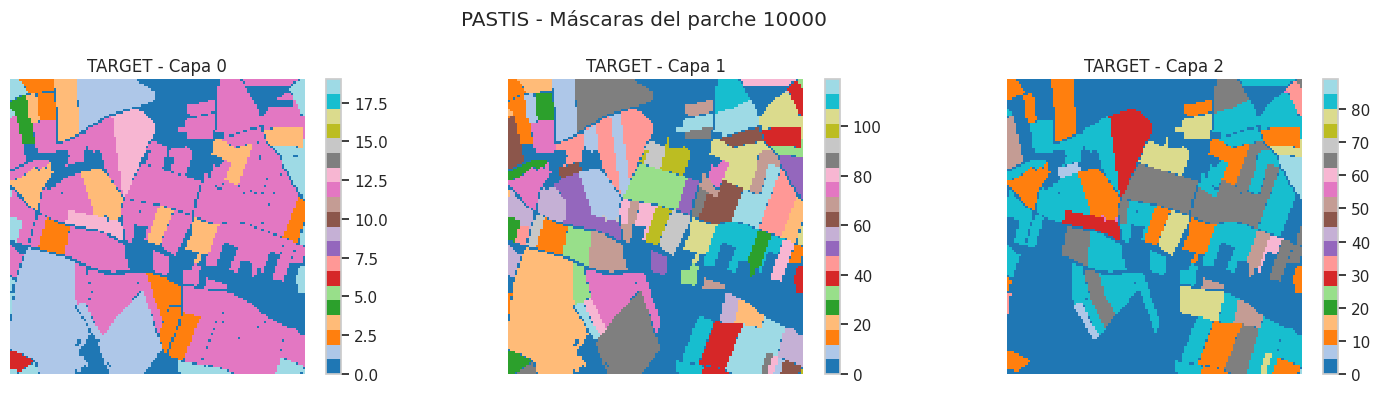

In [8]:
# ==============================================================================
# 1.8 ANÁLISIS DE LAS CAPAS DE LA MÁSCARA TARGET
# ==============================================================================

print("=== ANÁLISIS DE ETIQUETAS TARGET ===")

for i in range(mascara.shape[0]):
    valores, frecuencias = np.unique(
        mascara[i],
        return_counts=True
    )

    print(f"\nCapa {i}:")
    print("Número de valores únicos:", len(valores))
    print("Valores presentes:", valores)
    print("Valor mínimo:", valores.min())
    print("Valor máximo:", valores.max())

# Visualizar las tres capas
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    im = axes[i].imshow(
        mascara[i],
        cmap="tab20",
        interpolation="nearest"
    )

    axes[i].set_title(f"TARGET - Capa {i}")
    axes[i].axis("off")

    plt.colorbar(im, ax=axes[i], fraction=0.046)

plt.suptitle(f"PASTIS - Máscaras del parche {patch_id}")
plt.tight_layout()
plt.show()

In [9]:
# ==============================================================================
# 1.9 VERIFICACIÓN DE CORRESPONDENCIA ENTRE ETIQUETAS
# ==============================================================================

# Comparar clases semánticas e identificadores de parcelas
df_etiquetas = pd.DataFrame({
    "clase": mascara[0].flatten(),
    "parcela": mascara[1].flatten()
})

# Contar clases distintas por parcela
correspondencia = (
    df_etiquetas.groupby("parcela")["clase"]
    .nunique()
    .reset_index(name="clases_distintas")
)

print("=== CORRESPONDENCIA ENTRE CAPAS ===")

print("Total de identificadores:",
      len(correspondencia))

print("\nDistribución de clases por parcela:")
print(
    correspondencia["clases_distintas"]
    .value_counts()
    .sort_index()
)

print("\nParcelas con más de una clase:")
display(
    correspondencia[
        correspondencia["clases_distintas"] > 1
    ].head(10)
)

=== CORRESPONDENCIA ENTRE CAPAS ===
Total de identificadores: 117

Distribución de clases por parcela:
clases_distintas
1    117
Name: count, dtype: int64

Parcelas con más de una clase:


,parcela,clases_distintas


In [10]:
# ==============================================================================
# 1.10 VERIFICACIÓN DE ARCHIVOS PROCESADOS DEL AVANCE 2
# ==============================================================================

# Archivos generados durante la preparación de datos
archivos_avance2 = [
    "pastis_features_fe.pickle",
    "pastis_pipeline_metadata.pickle"
]

print("=== ARCHIVOS DEL AVANCE 2 ===")

for archivo in archivos_avance2:
    encontrados = []

    for carpeta in ["/content", pastis_path]:
        ruta = os.path.join(carpeta, archivo)

        if os.path.isfile(ruta):
            encontrados.append(ruta)

    if encontrados:
        print(f"\n{archivo}: ENCONTRADO")
        for ruta in encontrados:
            print("Ruta:", ruta)
    else:
        print(f"\n{archivo}: NO ENCONTRADO")

=== ARCHIVOS DEL AVANCE 2 ===

pastis_features_fe.pickle: NO ENCONTRADO

pastis_pipeline_metadata.pickle: NO ENCONTRADO


In [11]:
# ==============================================================================
# 1.11 VERIFICACIÓN DE BANDAS ESPECTRALES Y NORMALIZACIÓN
# ==============================================================================

# Bandas Sentinel-2 utilizadas en PASTIS
bandas_s2 = [
    "B2", "B3", "B4", "B5", "B6",
    "B7", "B8", "B8A", "B11", "B12"
]

print("=== BANDAS ESPECTRALES SENTINEL-2 ===")

for i, banda in enumerate(bandas_s2):
    print(f"Índice {i}: {banda}")

# Cargar parámetros de normalización
norm_path = os.path.join(pastis_path, "NORM_S2_patch.json")

with open(norm_path, "r") as f:
    norm_params = json.load(f)

print("\n=== PARÁMETROS DE NORMALIZACIÓN ===")
print("Claves disponibles:", list(norm_params.keys()))

# Mostrar un ejemplo de los parámetros
primera_clave = list(norm_params.keys())[0]

print("\nEjemplo de configuración:")
print(primera_clave)
print(norm_params[primera_clave])

=== BANDAS ESPECTRALES SENTINEL-2 ===
Índice 0: B2
Índice 1: B3
Índice 2: B4
Índice 3: B5
Índice 4: B6
Índice 5: B7
Índice 6: B8
Índice 7: B8A
Índice 8: B11
Índice 9: B12

=== PARÁMETROS DE NORMALIZACIÓN ===
Claves disponibles: ['Fold_1', 'Fold_2', 'Fold_3', 'Fold_4', 'Fold_5']

Ejemplo de configuración:
Fold_1
{'mean': [1165.9398193359375, 1375.6534423828125, 1429.2191162109375, 1764.798828125, 2719.273193359375, 3063.61181640625, 3205.90185546875, 3319.109619140625, 2422.904296875, 1639.370361328125], 'std': [1942.6156005859375, 1881.9234619140625, 1959.3798828125, 1867.2239990234375, 1754.5850830078125, 1769.4046630859375, 1784.860595703125, 1767.7100830078125, 1458.963623046875, 1299.2833251953125]}


In [12]:
# ==============================================================================
# 1.12 EXTRACCIÓN DE CARACTERÍSTICAS ESPECTRALES Y TEMPORALES
# ==============================================================================

def extraer_caracteristicas(imagen):

    # Reescalamiento físico de reflectancia
    img = imagen.astype(np.float32) / 10000.0

    # Bandas espectrales
    azul = img[:, 0]
    verde = img[:, 1]
    rojo = img[:, 2]
    nir = img[:, 6]

    eps = 1e-6

    # Índices espectrales
    ndvi = (nir - rojo) / (nir + rojo + eps)
    ndwi = (verde - nir) / (verde + nir + eps)

    evi = (
        2.5 * (nir - rojo) /
        (nir + 6 * rojo - 7.5 * azul + 1 + eps)
    )

    # Integrar bandas e índices
    indices = np.stack([ndvi, ndwi, evi], axis=1)
    datos = np.concatenate([img, indices], axis=1)

    # Estadísticas temporales
    media = np.mean(datos, axis=0)
    desviacion = np.std(datos, axis=0)
    minimo = np.min(datos, axis=0)
    maximo = np.max(datos, axis=0)

    # Construir matriz de características por píxel
    features = np.concatenate(
        [media, desviacion, minimo, maximo],
        axis=0
    )

    # Transformar (52, H, W) a (H*W, 52)
    X = features.reshape(features.shape[0], -1).T

    return X


# Probar extracción con el parche 10000
X_ejemplo = extraer_caracteristicas(imagen)

print("=== EXTRACCIÓN DE CARACTERÍSTICAS ===")
print("Dimensiones originales:", imagen.shape)
print("Matriz de características:", X_ejemplo.shape)
print("Número de características:", X_ejemplo.shape[1])
print("Valores finitos:", np.isfinite(X_ejemplo).all())

=== EXTRACCIÓN DE CARACTERÍSTICAS ===
Dimensiones originales: (43, 10, 128, 128)
Matriz de características: (16384, 52)
Número de características: 52
Valores finitos: True


In [13]:
# ==============================================================================
# 1.13 VALIDACIÓN DE CARACTERÍSTICAS EXTRAÍDAS
# ==============================================================================

# Nombres de las características
variables = bandas_s2 + ["NDVI", "NDWI", "EVI"]

estadisticas = ["media", "std", "min", "max"]

nombres_features = [
    f"{estadistica}_{variable}"
    for estadistica in estadisticas
    for variable in variables
]

# Resumen estadístico
df_features = pd.DataFrame(
    X_ejemplo,
    columns=nombres_features
)

print("=== VALIDACIÓN DE CARACTERÍSTICAS ===")

print("Dimensiones:", df_features.shape)
print("Valores faltantes:", df_features.isna().sum().sum())
print("Valores infinitos:",
      np.isinf(df_features.to_numpy()).sum())

# Revisar estadísticas de índices espectrales
columnas_indices = [
    col for col in df_features.columns
    if any(indice in col for indice in ["NDVI", "NDWI", "EVI"])
]

print("\n=== ESTADÍSTICAS DE ÍNDICES ESPECTRALES ===")
display(
    df_features[columnas_indices]
    .describe()
    .T
    .round(3)
)

=== VALIDACIÓN DE CARACTERÍSTICAS ===
Dimensiones: (16384, 52)
Valores faltantes: 0
Valores infinitos: 0

=== ESTADÍSTICAS DE ÍNDICES ESPECTRALES ===


,count,mean,std,min,25%,50%,75%,max
media_NDVI,16384.0,0.661,14.753,-18.309,0.341,0.417,0.520,1153.834
media_NDWI,16384.0,-0.964,26.796,-1870.325,-0.491,-0.405,-0.343,19.081
media_EVI,16384.0,0.290,1.067,-82.771,0.223,0.282,0.358,87.533
std_NDVI,16384.0,2.133,95.590,0.152,0.297,0.354,0.428,7475.406
std_NDWI,16384.0,4.234,173.645,0.083,0.287,0.340,0.439,12117.392
std_EVI,16384.0,0.642,6.868,0.076,0.195,0.250,0.315,565.555
min_NDVI,16384.0,-1.191,13.392,-813.051,-0.322,-0.043,-0.010,0.043
min_NDWI,16384.0,-26.147,1152.099,-80400.000,-1.471,-1.000,-0.883,-0.290
min_EVI,16384.0,-1.689,31.870,-3571.582,-0.467,-0.127,-0.049,0.055
max_NDVI,16384.0,12.423,634.165,0.754,1.000,1.034,1.750,49600.000


In [14]:
# ==============================================================================
# 1.14 DIAGNÓSTICO DE VALORES EXTREMOS EN ÍNDICES ESPECTRALES
# ==============================================================================

# Recuperar reflectancias del parche original
img = imagen.astype(np.float32) / 10000.0

azul = img[:, 0]
verde = img[:, 1]
rojo = img[:, 2]
nir = img[:, 6]

eps = 1e-6

# Calcular índices originales
ndvi = (nir - rojo) / (nir + rojo + eps)
ndwi = (verde - nir) / (verde + nir + eps)
evi = 2.5 * (nir - rojo) / (
    nir + 6 * rojo - 7.5 * azul + 1 + eps
)

print("=== DIAGNÓSTICO DE ÍNDICES ESPECTRALES ===")

for nombre, indice in [
    ("NDVI", ndvi),
    ("NDWI", ndwi),
    ("EVI", evi)
]:
    total = indice.size
    extremos = np.sum((indice < -1) | (indice > 1))

    print(f"\n{nombre}:")
    print("Total de observaciones:", total)
    print("Valores fuera de [-1, 1]:", extremos)
    print("Porcentaje:", round(extremos / total * 100, 2), "%")
    print("Mínimo:", round(float(indice.min()), 3))
    print("Máximo:", round(float(indice.max()), 3))

=== DIAGNÓSTICO DE ÍNDICES ESPECTRALES ===

NDVI:
Total de observaciones: 704512
Valores fuera de [-1, 1]: 29545
Porcentaje: 4.19 %
Mínimo: -813.051
Máximo: 49600.0

NDWI:
Total de observaciones: 704512
Valores fuera de [-1, 1]: 11880
Porcentaje: 1.69 %
Mínimo: -80400.0
Máximo: 839.38

EVI:
Total de observaciones: 704512
Valores fuera de [-1, 1]: 9177
Porcentaje: 1.3 %
Mínimo: -3571.582
Máximo: 3752.743


In [15]:
# ==============================================================================
# 1.15 EXTRACCIÓN DE CARACTERÍSTICAS CON ÍNDICES ESTABILIZADOS
# ==============================================================================

def extraer_caracteristicas(imagen):

    # Reescalamiento de reflectancia
    img = imagen.astype(np.float32) / 10000.0

    # Limitar reflectancias negativas
    img = np.maximum(img, 0.0)

    # Bandas espectrales
    azul = img[:, 0]
    verde = img[:, 1]
    rojo = img[:, 2]
    nir = img[:, 6]

    eps = 1e-4

    # Índices espectrales
    ndvi = (nir - rojo) / np.maximum(nir + rojo, eps)

    ndwi = (verde - nir) / np.maximum(verde + nir, eps)

    denominador_evi = (
        nir + 6 * rojo - 7.5 * azul + 1
    )

    # Preservar el signo del denominador de EVI
    denominador_evi = np.where(
        denominador_evi >= 0,
        np.maximum(denominador_evi, eps),
        np.minimum(denominador_evi, -eps)
    )

    evi = 2.5 * (nir - rojo) / denominador_evi

    # Limitar extremos de EVI como medida de estabilidad
    evi = np.clip(evi, -3, 3)

    # Integrar bandas e índices
    indices = np.stack([ndvi, ndwi, evi], axis=1)
    datos = np.concatenate([img, indices], axis=1)

    # Estadísticas temporales
    features = np.concatenate([
        np.mean(datos, axis=0),
        np.std(datos, axis=0),
        np.min(datos, axis=0),
        np.max(datos, axis=0)
    ], axis=0)

    return features.reshape(features.shape[0], -1).T


# Verificar la nueva extracción
X_ejemplo = extraer_caracteristicas(imagen)

df_features = pd.DataFrame(
    X_ejemplo,
    columns=nombres_features
)

print("=== VALIDACIÓN DE CARACTERÍSTICAS CORREGIDAS ===")
print("Dimensiones:", X_ejemplo.shape)
print("Valores finitos:", np.isfinite(X_ejemplo).all())

print("\n=== ESTADÍSTICAS DE ÍNDICES ESPECTRALES ===")

display(
    df_features[columnas_indices]
    .describe()
    .T
    .round(3)
)

=== VALIDACIÓN DE CARACTERÍSTICAS CORREGIDAS ===
Dimensiones: (16384, 52)
Valores finitos: True

=== ESTADÍSTICAS DE ÍNDICES ESPECTRALES ===


,count,mean,std,min,25%,50%,75%,max
media_NDVI,16384.0,0.405,0.109,0.056,0.327,0.390,0.483,0.688
media_NDWI,16384.0,-0.423,0.078,-0.638,-0.479,-0.414,-0.370,-0.075
media_EVI,16384.0,0.289,0.086,-0.013,0.225,0.280,0.349,0.547
std_NDVI,16384.0,0.297,0.054,0.078,0.264,0.305,0.339,0.445
std_NDWI,16384.0,0.273,0.040,0.078,0.249,0.278,0.305,0.376
std_EVI,16384.0,0.276,0.120,0.074,0.194,0.248,0.312,0.849
min_NDVI,16384.0,-0.064,0.159,-1.000,-0.060,-0.022,-0.003,0.040
min_NDWI,16384.0,-0.954,0.097,-1.000,-1.000,-1.000,-1.000,-0.290
min_EVI,16384.0,-0.471,0.801,-3.000,-0.465,-0.126,-0.026,0.064
max_NDVI,16384.0,0.967,0.089,0.270,1.000,1.000,1.000,1.000


### Preparación del subconjunto experimental

Para realizar una primera evaluación del algoritmo Random Forest, se selecciona un subconjunto reducido del dataset PASTIS, conservando la separación previamente establecida entre entrenamiento, validación y prueba.

A partir de las imágenes seleccionadas se extraen las características espectrales y temporales, junto con sus respectivas etiquetas de segmentación. Posteriormente, se analiza la distribución de clases para identificar posibles desequilibrios que puedan influir en el desempeño del modelo.

In [16]:
# ==============================================================================
# 1.16 SELECCIÓN DE SUBCONJUNTO EXPERIMENTAL PARA EL BASELINE
# ==============================================================================

# Identificar las particiones creadas anteriormente
print("=== VARIABLES DE PARTICIÓN DISPONIBLES ===")

for nombre in [
    "train_ids", "val_ids", "test_ids",
    "train_patches", "val_patches", "test_patches"
]:
    if nombre in globals():
        variable = globals()[nombre]
        print(f"{nombre}: {len(variable)} elementos")

# Seleccionar subconjuntos reproducibles desde los metadatos
rng = np.random.default_rng(42)

def seleccionar_parches(df, cantidad):
    ids = df["ID_PATCH"].to_numpy()
    return rng.choice(
        ids,
        size=min(cantidad, len(ids)),
        replace=False
    ).tolist()

train_sample = seleccionar_parches(
    metadata[metadata["Fold"].isin([1, 2, 3])], 20
)

val_sample = seleccionar_parches(
    metadata[metadata["Fold"] == 4], 5
)

test_sample = seleccionar_parches(
    metadata[metadata["Fold"] == 5], 5
)

print("\n=== SUBCONJUNTO EXPERIMENTAL ===")
print("Entrenamiento:", len(train_sample), "parches")
print("Validación:", len(val_sample), "parches")
print("Prueba:", len(test_sample), "parches")

print("\nPrimeros IDs de entrenamiento:", train_sample[:5])

=== VARIABLES DE PARTICIÓN DISPONIBLES ===
train_ids: 1455 elementos
val_ids: 482 elementos
test_ids: 496 elementos

=== SUBCONJUNTO EXPERIMENTAL ===
Entrenamiento: 20 parches
Validación: 5 parches
Prueba: 5 parches

Primeros IDs de entrenamiento: [30736, 30621, 10528, 40480, 40174]


In [17]:
# ==============================================================================
# 1.17 PREPARACIÓN DE DATOS PARA EL MODELO BASELINE
# ==============================================================================

# Configuración experimental
PIXELS_POR_PARCHE = 2000
rng = np.random.default_rng(42)

def preparar_datos(ids, nombre_conjunto):

    X_lista = []
    y_lista = []

    for patch_id_actual in tqdm(ids, desc=nombre_conjunto):

        # Cargar imagen y etiquetas
        ruta_img = os.path.join(
            pastis_path, "DATA_S2",
            f"S2_{patch_id_actual}.npy"
        )

        ruta_target = os.path.join(
            pastis_path, "ANNOTATIONS",
            f"TARGET_{patch_id_actual}.npy"
        )

        img = np.load(ruta_img)
        target = np.load(ruta_target)

        # Extraer características y etiquetas semánticas
        X = extraer_caracteristicas(img)
        y = target[0].reshape(-1)

        # Seleccionar píxeles aleatoriamente
        n = min(PIXELS_POR_PARCHE, len(y))
        indices = rng.choice(len(y), size=n, replace=False)

        X_lista.append(X[indices])
        y_lista.append(y[indices])

    X_final = np.vstack(X_lista)
    y_final = np.concatenate(y_lista)

    print(f"\n=== {nombre_conjunto.upper()} ===")
    print("Características:", X_final.shape)
    print("Etiquetas:", y_final.shape)
    print("Clases presentes:", np.unique(y_final))

    return X_final, y_final


# Preparar los tres conjuntos
X_train, y_train = preparar_datos(train_sample, "Entrenamiento")
X_val, y_val = preparar_datos(val_sample, "Validación")
X_test, y_test = preparar_datos(test_sample, "Prueba")

print("\nPreparación de datos completada.")

Entrenamiento:   0%|          | 0/20 [00:00<?, ?it/s]


=== ENTRENAMIENTO ===
Características: (40000, 52)
Etiquetas: (40000,)
Clases presentes: [ 0  1  2  3  4  5  7  8  9 10 11 12 13 14 15 16 17 18 19]


Validación:   0%|          | 0/5 [00:00<?, ?it/s]


=== VALIDACIÓN ===
Características: (10000, 52)
Etiquetas: (10000,)
Clases presentes: [ 0  1  2  3  4  5  6  7  9 10 12 13 14 15 16 17 18 19]


Prueba:   0%|          | 0/5 [00:00<?, ?it/s]


=== PRUEBA ===
Características: (10000, 52)
Etiquetas: (10000,)
Clases presentes: [ 0  1  2  3  4  5  7  8 14 15 17 19]

Preparación de datos completada.


=== DISTRIBUCIÓN DE CLASES ===


,Clase,Entrenamiento,Validación,Prueba
0,0,14480,4066,3796
1,1,9256,1655,3274
2,2,3965,796,489
3,3,3373,1587,1184
4,4,452,64,32
5,5,575,91,102
6,6,0,14,0
7,7,138,106,13
8,8,1325,0,3
9,9,629,310,0


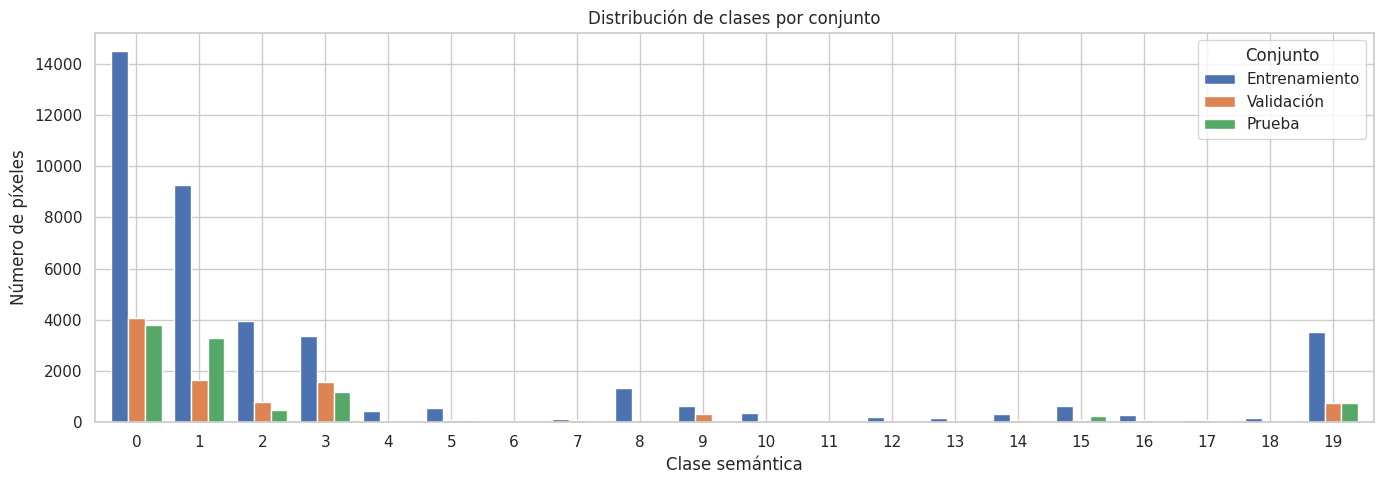


Clases ausentes en entrenamiento: [6]


In [18]:
# ==============================================================================
# 1.18 ANÁLISIS DE DISTRIBUCIÓN DE CLASES
# ==============================================================================

# Obtener frecuencias por clase
clases = np.union1d(
    np.union1d(np.unique(y_train), np.unique(y_val)),
    np.unique(y_test)
)

distribucion = pd.DataFrame({
    "Clase": clases,
    "Entrenamiento": [
        np.sum(y_train == c) for c in clases
    ],
    "Validación": [
        np.sum(y_val == c) for c in clases
    ],
    "Prueba": [
        np.sum(y_test == c) for c in clases
    ]
})

print("=== DISTRIBUCIÓN DE CLASES ===")
display(distribucion)

# Visualización
ax = distribucion.set_index("Clase").plot(
    kind="bar",
    figsize=(14, 5),
    width=0.8
)

plt.title("Distribución de clases por conjunto")
plt.xlabel("Clase semántica")
plt.ylabel("Número de píxeles")
plt.xticks(rotation=0)
plt.legend(title="Conjunto")
plt.tight_layout()
plt.show()

# Identificar clases ausentes en entrenamiento
clases_ausentes = np.setdiff1d(
    np.union1d(np.unique(y_val), np.unique(y_test)),
    np.unique(y_train)
)

print("\nClases ausentes en entrenamiento:",
      clases_ausentes)

## 2. Selección y Entrenamiento del Algoritmo Baseline

Para establecer un punto de referencia en la segmentación de cultivos, se utiliza el algoritmo Random Forest, un método de aprendizaje supervisado basado en múltiples árboles de decisión.

El modelo se entrena utilizando las 52 características espectrales y temporales extraídas de las imágenes Sentinel-2. Se emplea una configuración inicial de 100 árboles, profundidad máxima de 20 niveles y ponderación de clases para considerar el desequilibrio observado en los datos.

Esta primera implementación permitirá evaluar el desempeño del algoritmo antes de realizar ajustes o comparaciones posteriores.

In [19]:
# ==============================================================================
# 2.1 ENTRENAMIENTO DEL MODELO BASELINE - RANDOM FOREST
# ==============================================================================

# Configuración del modelo
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("=== ENTRENAMIENTO RANDOM FOREST BASELINE ===")

# Entrenamiento
inicio = time.time()

modelo_rf.fit(X_train, y_train)

tiempo_entrenamiento = time.time() - inicio

print("Entrenamiento completado.")
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} segundos")

# Predicciones
pred_train = modelo_rf.predict(X_train)
pred_val = modelo_rf.predict(X_val)

# Evaluación inicial
print("\n=== RESULTADOS INICIALES ===")

for nombre, y_real, y_pred in [
    ("Entrenamiento", y_train, pred_train),
    ("Validación", y_val, pred_val)
]:
    print(f"\n{nombre}:")
    print("Accuracy:",
          round(accuracy_score(y_real, y_pred), 4))
    print("Macro F1:",
          round(f1_score(
              y_real, y_pred,
              average="macro",
              zero_division=0
          ), 4))
    print("Macro IoU:",
          round(jaccard_score(
              y_real, y_pred,
              average="macro",
              zero_division=0
          ), 4))

=== ENTRENAMIENTO RANDOM FOREST BASELINE ===
Entrenamiento completado.
Tiempo de entrenamiento: 52.65 segundos

=== RESULTADOS INICIALES ===

Entrenamiento:
Accuracy: 0.982
Macro F1: 0.991
Macro IoU: 0.9825

Validación:
Accuracy: 0.5142
Macro F1: 0.1542
Macro IoU: 0.1075


## 3. Evaluación e Interpretación del Modelo Baseline

Una vez entrenado el modelo Random Forest, se realiza una evaluación más detallada de su desempeño mediante métricas de clasificación y el análisis de las características utilizadas.

Se revisan los resultados por clase y la importancia de las variables espectrales y temporales, con el propósito de identificar cuáles contribuyen en mayor medida a las predicciones del modelo.

Este análisis también permite reconocer limitaciones iniciales que deberán considerarse al evaluar su capacidad de generalización.

=== REPORTE DE CLASIFICACIÓN - VALIDACIÓN ===


,precision,recall,f1-score,support
0,0.755,0.656,0.702,4066.000
1,0.547,0.689,0.610,1655.000
2,0.399,0.451,0.423,796.000
3,0.344,0.434,0.384,1587.000
4,0.000,0.000,0.000,64.000
5,0.000,0.000,0.000,91.000
6,0.000,0.000,0.000,14.000
7,0.000,0.000,0.000,106.000
8,0.000,0.000,0.000,0.000
9,0.954,0.468,0.628,310.000


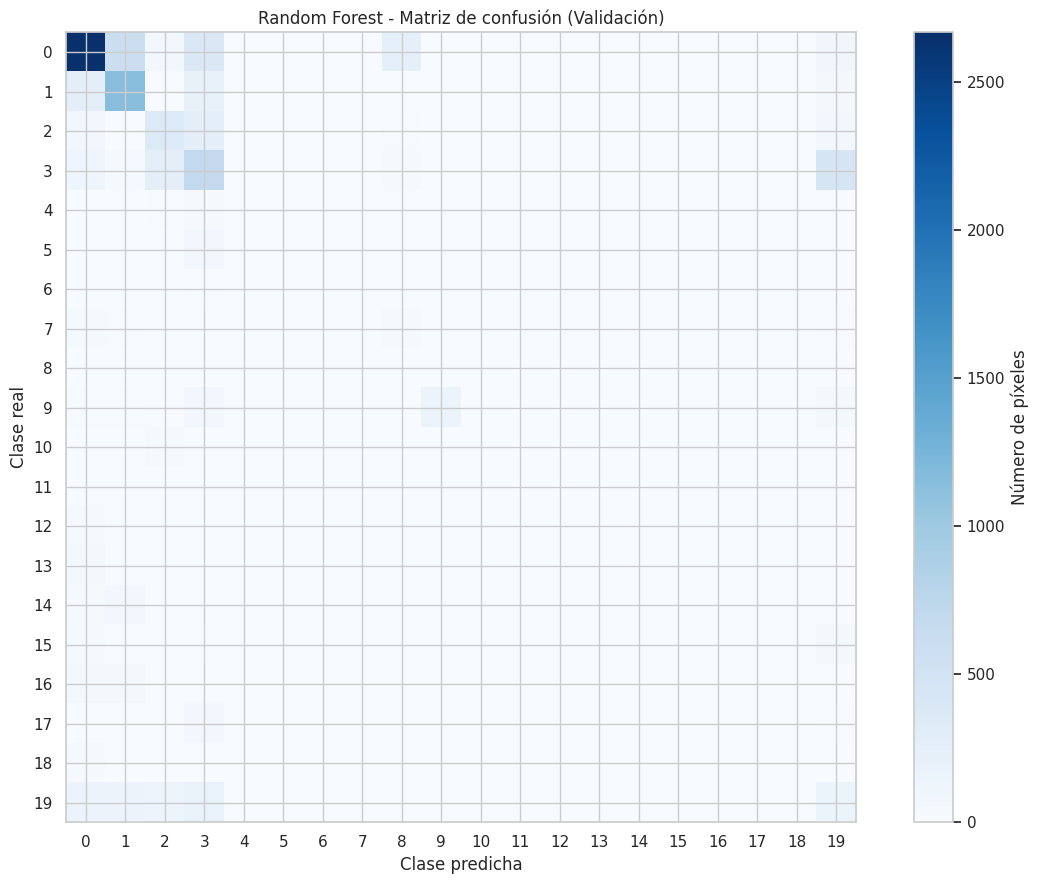


=== CLASES CON MENOR F1-SCORE ===


,precision,recall,f1-score,support
7,0.0,0.0,0.0,106.0
6,0.0,0.0,0.0,14.0
5,0.0,0.0,0.0,91.0
4,0.0,0.0,0.0,64.0
12,0.0,0.0,0.0,29.0
11,0.0,0.0,0.0,0.0
10,0.0,0.0,0.0,48.0
8,0.0,0.0,0.0,0.0
14,0.0,0.0,0.0,100.0
13,0.0,0.0,0.0,51.0


In [20]:
# ==============================================================================
# 3.1 EVALUACIÓN DETALLADA DEL MODELO RANDOM FOREST
# ==============================================================================

print("=== REPORTE DE CLASIFICACIÓN - VALIDACIÓN ===")

# Identificar todas las clases presentes
clases = np.union1d(
    np.unique(y_train),
    np.unique(y_val)
)

# Reporte de clasificación
reporte = classification_report(
    y_val,
    pred_val,
    labels=clases,
    output_dict=True,
    zero_division=0
)

reporte_df = pd.DataFrame(reporte).transpose()

display(reporte_df.round(3))

# Matriz de confusión
matriz = confusion_matrix(
    y_val,
    pred_val,
    labels=clases
)

plt.figure(figsize=(12, 9))
plt.imshow(matriz, interpolation="nearest", cmap="Blues")
plt.title("Random Forest - Matriz de confusión (Validación)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.xticks(range(len(clases)), clases)
plt.yticks(range(len(clases)), clases)
plt.colorbar(label="Número de píxeles")
plt.tight_layout()
plt.show()

# Identificar clases con peor desempeño
print("\n=== CLASES CON MENOR F1-SCORE ===")

reporte_clases = reporte_df.loc[
    [str(c) for c in clases]
]

display(
    reporte_clases.sort_values("f1-score").head(10).round(3)
)

=== IMPORTANCIA DE CARACTERÍSTICAS ===


,Característica,Importancia
10,Feature_10,0.037265
4,Feature_4,0.034263
23,Feature_23,0.032987
9,Feature_9,0.032943
12,Feature_12,0.030157
24,Feature_24,0.030156
8,Feature_8,0.030082
5,Feature_5,0.028864
11,Feature_11,0.028792
7,Feature_7,0.026157


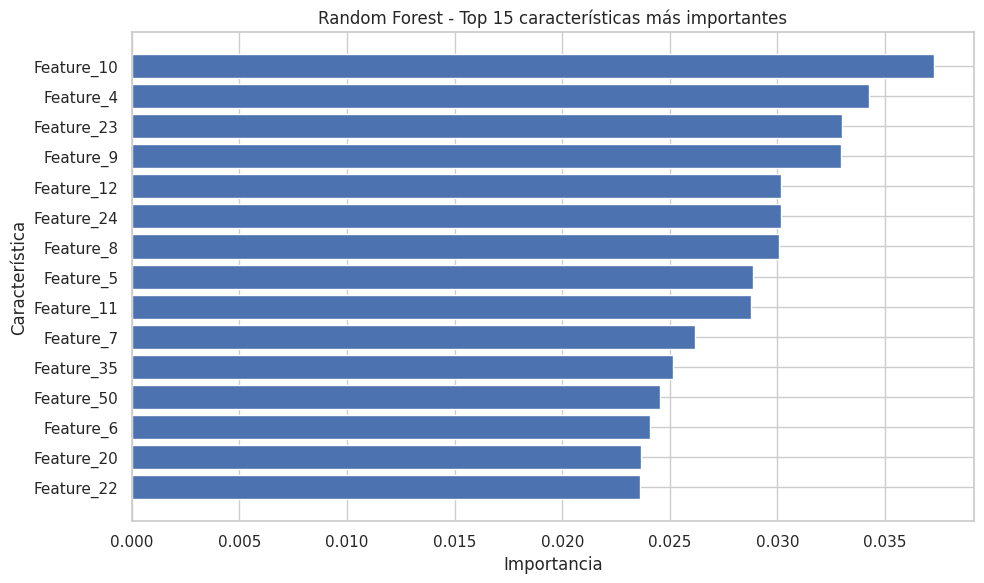

In [21]:
# ==============================================================================
# 3.2 IMPORTANCIA DE CARACTERÍSTICAS DEL RANDOM FOREST
# ==============================================================================

# Obtener importancia de características
importancias = modelo_rf.feature_importances_

# Crear tabla de resultados
df_importancias = pd.DataFrame({
    "Característica": [f"Feature_{i}" for i in range(len(importancias))],
    "Importancia": importancias
}).sort_values("Importancia", ascending=False)

print("=== IMPORTANCIA DE CARACTERÍSTICAS ===")
display(df_importancias.head(15))

# Visualizar las 15 características más importantes
top15 = df_importancias.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top15["Característica"][::-1],
    top15["Importancia"][::-1]
)

plt.title("Random Forest - Top 15 características más importantes")
plt.xlabel("Importancia")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

In [22]:
# ==============================================================================
# 3.3 IDENTIFICACIÓN DE NOMBRES DE CARACTERÍSTICAS
# ==============================================================================

print("=== VARIABLES DE CARACTERÍSTICAS DISPONIBLES ===")

for nombre, objeto in globals().copy().items():
    if isinstance(objeto, (list, tuple, pd.Index)):
        if len(objeto) == 52 and all(isinstance(x, str) for x in objeto):
            print(f"\nVariable encontrada: {nombre}")
            print(list(objeto))

=== VARIABLES DE CARACTERÍSTICAS DISPONIBLES ===

Variable encontrada: nombres_features
['media_B2', 'media_B3', 'media_B4', 'media_B5', 'media_B6', 'media_B7', 'media_B8', 'media_B8A', 'media_B11', 'media_B12', 'media_NDVI', 'media_NDWI', 'media_EVI', 'std_B2', 'std_B3', 'std_B4', 'std_B5', 'std_B6', 'std_B7', 'std_B8', 'std_B8A', 'std_B11', 'std_B12', 'std_NDVI', 'std_NDWI', 'std_EVI', 'min_B2', 'min_B3', 'min_B4', 'min_B5', 'min_B6', 'min_B7', 'min_B8', 'min_B8A', 'min_B11', 'min_B12', 'min_NDVI', 'min_NDWI', 'min_EVI', 'max_B2', 'max_B3', 'max_B4', 'max_B5', 'max_B6', 'max_B7', 'max_B8', 'max_B8A', 'max_B11', 'max_B12', 'max_NDVI', 'max_NDWI', 'max_EVI']


=== TOP 15 CARACTERÍSTICAS MÁS IMPORTANTES ===


,Característica,Importancia
10,media_NDVI,0.037265
4,media_B6,0.034263
23,std_NDVI,0.032987
9,media_B12,0.032943
12,media_EVI,0.030157
24,std_NDWI,0.030156
8,media_B11,0.030082
5,media_B7,0.028864
11,media_NDWI,0.028792
7,media_B8A,0.026157


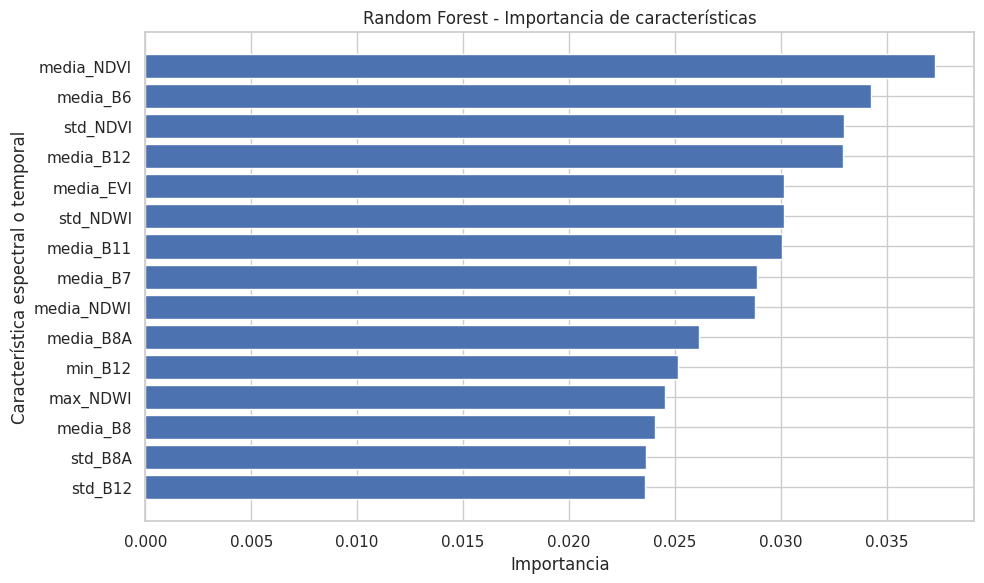

In [23]:
# ==============================================================================
# 3.4 IMPORTANCIA DE CARACTERÍSTICAS CON NOMBRES REALES
# ==============================================================================

# Crear tabla con nombres originales
df_importancias = pd.DataFrame({
    "Característica": nombres_features,
    "Importancia": modelo_rf.feature_importances_
}).sort_values("Importancia", ascending=False)

print("=== TOP 15 CARACTERÍSTICAS MÁS IMPORTANTES ===")
display(df_importancias.head(15))

# Visualización
top15 = df_importancias.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top15["Característica"][::-1],
    top15["Importancia"][::-1]
)

plt.title("Random Forest - Importancia de características")
plt.xlabel("Importancia")
plt.ylabel("Característica espectral o temporal")
plt.tight_layout()
plt.show()

## 4. Diagnóstico de sobreajuste y generalización

Se analiza el desempeño del modelo Random Forest en los conjuntos de entrenamiento y validación para identificar posibles problemas de sobreajuste.

Se calculan métricas de clasificación bajo un mismo criterio de evaluación, considerando la exactitud (Accuracy), F1-score macro e Intersection over Union (IoU) macro.

Esta comparación permitirá determinar qué tan bien generaliza el modelo a imágenes satelitales no utilizadas durante el entrenamiento.

In [24]:
# ============================================================
# 4.1 DIAGNÓSTICO DE SOBREAJUSTE Y GENERALIZACIÓN
# ============================================================

# Utilizar el modelo Random Forest entrenado
modelo = modelo_rf

# Obtener predicciones
pred_train = modelo.predict(X_train)
pred_val = modelo.predict(X_val)

# Definir clases para una evaluación consistente
clases = np.union1d(y_train, y_val)

# Calcular métricas
def calcular_metricas(y_real, y_pred):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Macro F1": f1_score(
            y_real, y_pred,
            labels=clases,
            average="macro",
            zero_division=0
        ),
        "Macro IoU": jaccard_score(
            y_real, y_pred,
            labels=clases,
            average="macro",
            zero_division=0
        )
    }

metricas_train = calcular_metricas(y_train, pred_train)
metricas_val = calcular_metricas(y_val, pred_val)

# Crear tabla comparativa
comparacion = pd.DataFrame({
    "Entrenamiento": metricas_train,
    "Validación": metricas_val
})

comparacion["Diferencia"] = (
    comparacion["Entrenamiento"] -
    comparacion["Validación"]
)

print("=== DIAGNÓSTICO DE GENERALIZACIÓN ===")
display(comparacion.round(4))

print("\n=== INTERPRETACIÓN INICIAL ===")

diferencia_accuracy = comparacion.loc["Accuracy", "Diferencia"]

print(f"Diferencia de Accuracy: {diferencia_accuracy:.4f}")

if diferencia_accuracy > 0.20:
    print("Se observa una diferencia considerable entre entrenamiento y validación.")
    print("Los resultados sugieren un posible sobreajuste del modelo.")
else:
    print("La diferencia de Accuracy no supera el umbral exploratorio de 0.20.")
    print("Es necesario revisar también las métricas por clase.")

=== DIAGNÓSTICO DE GENERALIZACIÓN ===


,Entrenamiento,Validación,Diferencia
Accuracy,0.9820,0.5142,0.4678
Macro F1,0.9415,0.1465,0.7950
Macro IoU,0.9333,0.1021,0.8312



=== INTERPRETACIÓN INICIAL ===
Diferencia de Accuracy: 0.4678
Se observa una diferencia considerable entre entrenamiento y validación.
Los resultados sugieren un posible sobreajuste del modelo.


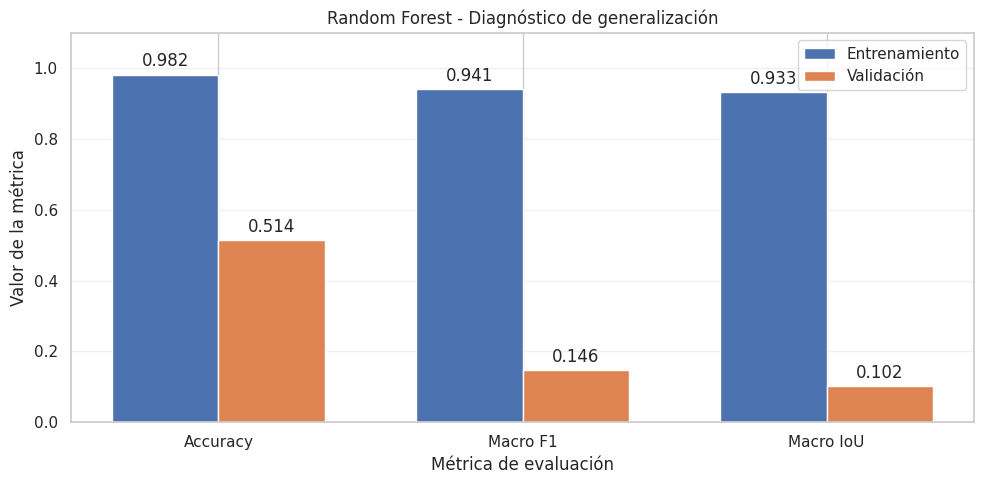

In [25]:
# ============================================================
# 4.2 VISUALIZACIÓN DEL DIAGNÓSTICO DE GENERALIZACIÓN
# ============================================================

metricas = comparacion.index.tolist()

valores_train = comparacion["Entrenamiento"].values
valores_val = comparacion["Validación"].values

x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

barras_train = ax.bar(
    x - ancho/2,
    valores_train,
    ancho,
    label="Entrenamiento"
)

barras_val = ax.bar(
    x + ancho/2,
    valores_val,
    ancho,
    label="Validación"
)

ax.set_title(
    "Random Forest - Diagnóstico de generalización"
)

ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("Métrica de evaluación")

ax.set_xticks(x)
ax.set_xticklabels(metricas)

ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.bar_label(barras_train, fmt="%.3f", padding=3)
ax.bar_label(barras_val, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

### 4.3 Optimización de hiperparámetros del Random Forest

A partir del diagnóstico de generalización, se propone una segunda configuración del modelo Random Forest con restricciones sobre la complejidad de los árboles.

El objetivo es reducir el sobreajuste observado en el modelo inicial y evaluar si estas modificaciones permiten mejorar el desempeño sobre el conjunto de validación.

Se conservarán las mismas características espectrales y temporales, así como las particiones de entrenamiento y validación, para mantener una comparación consistente.

In [26]:
# ============================================================
# 4.3 ENTRENAMIENTO DE RANDOM FOREST REGULARIZADO
# ============================================================

# Configurar modelo con menor complejidad
modelo_rf_optimizado = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

print("=== ENTRENAMIENTO RANDOM FOREST REGULARIZADO ===")

inicio = time.time()

modelo_rf_optimizado.fit(X_train, y_train)

tiempo_entrenamiento = time.time() - inicio

print("Entrenamiento completado.")
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} segundos")

# Predicciones
pred_train_opt = modelo_rf_optimizado.predict(X_train)
pred_val_opt = modelo_rf_optimizado.predict(X_val)

# Evaluación con las mismas clases del diagnóstico anterior
metricas_train_opt = calcular_metricas(y_train, pred_train_opt)
metricas_val_opt = calcular_metricas(y_val, pred_val_opt)

# Tabla de resultados
comparacion_opt = pd.DataFrame({
    "Entrenamiento": metricas_train_opt,
    "Validación": metricas_val_opt
})

comparacion_opt["Diferencia"] = (
    comparacion_opt["Entrenamiento"] -
    comparacion_opt["Validación"]
)

print("\n=== RESULTADOS RANDOM FOREST REGULARIZADO ===")
display(comparacion_opt.round(4))

# Comparación contra el baseline original
comparacion_modelos = pd.DataFrame({
    "Baseline": metricas_val,
    "Regularizado": metricas_val_opt
})

comparacion_modelos["Cambio"] = (
    comparacion_modelos["Regularizado"] -
    comparacion_modelos["Baseline"]
)

print("\n=== COMPARACIÓN DE MODELOS EN VALIDACIÓN ===")
display(comparacion_modelos.round(4))

=== ENTRENAMIENTO RANDOM FOREST REGULARIZADO ===
Entrenamiento completado.
Tiempo de entrenamiento: 38.64 segundos

=== RESULTADOS RANDOM FOREST REGULARIZADO ===


,Entrenamiento,Validación,Diferencia
Accuracy,0.8268,0.5326,0.2942
Macro F1,0.6843,0.1476,0.5367
Macro IoU,0.5628,0.1046,0.4582



=== COMPARACIÓN DE MODELOS EN VALIDACIÓN ===


,Baseline,Regularizado,Cambio
Accuracy,0.5142,0.5326,0.0184
Macro F1,0.1465,0.1476,0.0011
Macro IoU,0.1021,0.1046,0.0025


### 4.4 Comparación del modelo baseline y regularizado

Se comparan los resultados obtenidos por el Random Forest inicial y su versión regularizada utilizando el conjunto de validación.

El análisis permite identificar el efecto de las restricciones aplicadas a la complejidad de los árboles y determinar si estas modificaciones contribuyen a mejorar la capacidad de generalización.

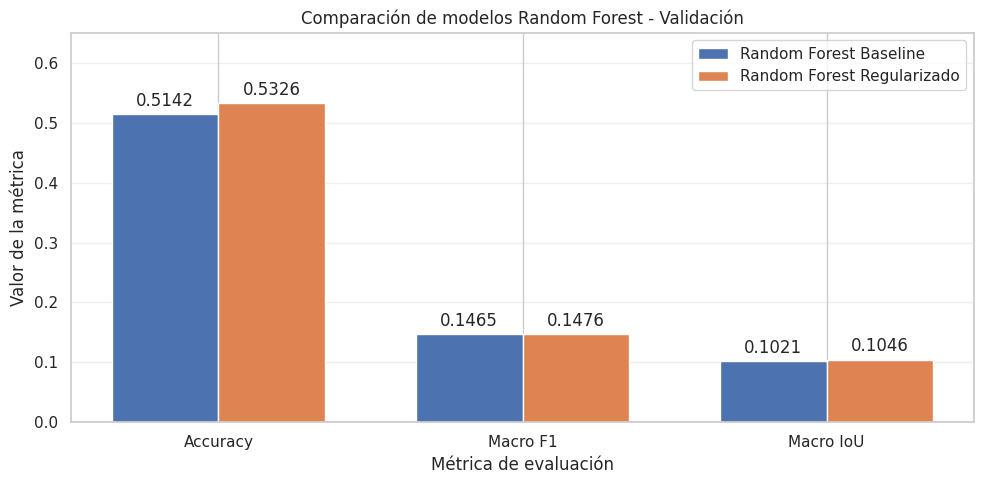

In [27]:
# ============================================================
# 4.4 COMPARACIÓN VISUAL DE MODELOS
# ============================================================

metricas = comparacion_modelos.index.tolist()

baseline = comparacion_modelos["Baseline"].values
regularizado = comparacion_modelos["Regularizado"].values

x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

barras_baseline = ax.bar(
    x - ancho/2,
    baseline,
    ancho,
    label="Random Forest Baseline"
)

barras_regularizado = ax.bar(
    x + ancho/2,
    regularizado,
    ancho,
    label="Random Forest Regularizado"
)

ax.set_title("Comparación de modelos Random Forest - Validación")
ax.set_xlabel("Métrica de evaluación")
ax.set_ylabel("Valor de la métrica")

ax.set_xticks(x)
ax.set_xticklabels(metricas)

ax.set_ylim(0, 0.65)
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.bar_label(barras_baseline, fmt="%.4f", padding=3)
ax.bar_label(barras_regularizado, fmt="%.4f", padding=3)

plt.tight_layout()
plt.show()

### 4.5 Evaluación del balanceo de clases

Debido al desbalance observado en la distribución de clases del conjunto de entrenamiento, se realizará un experimento adicional utilizando ponderación automática de clases.

Se utilizará el parámetro `class_weight="balanced_subsample"` del algoritmo Random Forest, que ajusta los pesos de las clases según su frecuencia en las muestras bootstrap de cada árbol.

El objetivo es evaluar si esta estrategia mejora el reconocimiento de las clases menos representadas, utilizando las mismas particiones y características del experimento anterior.

In [28]:
# ============================================================
# 4.5 RANDOM FOREST CON BALANCEO DE CLASES
# ============================================================

# Configurar modelo con ponderación de clases
modelo_rf_balanceado = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("=== ENTRENAMIENTO RANDOM FOREST BALANCEADO ===")

inicio = time.time()

modelo_rf_balanceado.fit(X_train, y_train)

tiempo_balanceado = time.time() - inicio

print("Entrenamiento completado.")
print(f"Tiempo de entrenamiento: {tiempo_balanceado:.2f} segundos")

# Predicciones
pred_train_bal = modelo_rf_balanceado.predict(X_train)
pred_val_bal = modelo_rf_balanceado.predict(X_val)

# Evaluación
metricas_train_bal = calcular_metricas(y_train, pred_train_bal)
metricas_val_bal = calcular_metricas(y_val, pred_val_bal)

# Comparación de los tres modelos
comparacion_tres_modelos = pd.DataFrame({
    "Baseline": metricas_val,
    "Regularizado": metricas_val_opt,
    "Balanceado": metricas_val_bal
})

print("\n=== COMPARACIÓN DE MODELOS EN VALIDACIÓN ===")
display(comparacion_tres_modelos.round(4))

# Diferencia respecto al modelo regularizado
comparacion_balanceo = pd.DataFrame({
    "Regularizado": metricas_val_opt,
    "Balanceado": metricas_val_bal
})

comparacion_balanceo["Cambio"] = (
    comparacion_balanceo["Balanceado"] -
    comparacion_balanceo["Regularizado"]
)

print("\n=== EFECTO DEL BALANCEO DE CLASES ===")
display(comparacion_balanceo.round(4))

=== ENTRENAMIENTO RANDOM FOREST BALANCEADO ===
Entrenamiento completado.
Tiempo de entrenamiento: 39.65 segundos

=== COMPARACIÓN DE MODELOS EN VALIDACIÓN ===


,Baseline,Regularizado,Balanceado
Accuracy,0.5142,0.5326,0.4520
Macro F1,0.1465,0.1476,0.1628
Macro IoU,0.1021,0.1046,0.1084



=== EFECTO DEL BALANCEO DE CLASES ===


,Regularizado,Balanceado,Cambio
Accuracy,0.5326,0.4520,-0.0806
Macro F1,0.1476,0.1628,0.0152
Macro IoU,0.1046,0.1084,0.0038


### 4.6 Análisis del desempeño por clase

Se realiza una evaluación detallada del desempeño de los modelos Random Forest regularizado y balanceado sobre el conjunto de validación.

El análisis considera las métricas de precisión, recall y F1-score para cada clase semántica, con el propósito de identificar aquellas que presentan mejoras o dificultades de clasificación.

Esta evaluación permitirá determinar si la ponderación de clases contribuye a reconocer categorías minoritarias y comprender las limitaciones del modelo.

In [29]:
# ============================================================
# 4.6 COMPARACIÓN DEL DESEMPEÑO POR CLASE
# ============================================================

# Obtener reportes de clasificación
reporte_reg = classification_report(
    y_val,
    pred_val_opt,
    labels=clases,
    output_dict=True,
    zero_division=0
)

reporte_bal = classification_report(
    y_val,
    pred_val_bal,
    labels=clases,
    output_dict=True,
    zero_division=0
)

# Crear tabla comparativa
resultados_clases = pd.DataFrame({
    "Clase": clases,
    "Soporte": [
        reporte_reg[str(c)]["support"] for c in clases
    ],
    "F1 Regularizado": [
        reporte_reg[str(c)]["f1-score"] for c in clases
    ],
    "F1 Balanceado": [
        reporte_bal[str(c)]["f1-score"] for c in clases
    ]
})

# Calcular diferencia
resultados_clases["Cambio F1"] = (
    resultados_clases["F1 Balanceado"] -
    resultados_clases["F1 Regularizado"]
)

print("=== COMPARACIÓN DE F1-SCORE POR CLASE ===")
display(resultados_clases.round(4))

# Identificar clases que mejoraron
mejoraron = resultados_clases[
    resultados_clases["Cambio F1"] > 0
]

empeoraron = resultados_clases[
    resultados_clases["Cambio F1"] < 0
]

print("\n=== RESUMEN DEL BALANCEO ===")
print("Clases que mejoraron:", len(mejoraron))
print("Clases que empeoraron:", len(empeoraron))

print("\nClases con mayor mejora:")
display(
    resultados_clases.sort_values(
        "Cambio F1",
        ascending=False
    ).head(10).round(4)
)

=== COMPARACIÓN DE F1-SCORE POR CLASE ===


,Clase,Soporte,F1 Regularizado,F1 Balanceado,Cambio F1
0,0,4066.0,0.7149,0.6178,-0.0971
1,1,1655.0,0.6273,0.5776,-0.0496
2,2,796.0,0.4321,0.4139,-0.0182
3,3,1587.0,0.3849,0.3880,0.0031
4,4,64.0,0.0000,0.0190,0.0190
5,5,91.0,0.0000,0.0128,0.0128
6,6,14.0,0.0000,0.0000,0.0000
7,7,106.0,0.0000,0.0000,0.0000
8,8,0.0,0.0000,0.0000,0.0000
9,9,310.0,0.6625,0.6352,-0.0273



=== RESUMEN DEL BALANCEO ===
Clases que mejoraron: 7
Clases que empeoraron: 4

Clases con mayor mejora:


,Clase,Soporte,F1 Regularizado,F1 Balanceado,Cambio F1
13,13,51.0,0.0000,0.3059,0.3059
12,12,29.0,0.0000,0.0896,0.0896
15,15,100.0,0.0000,0.0588,0.0588
4,4,64.0,0.0000,0.0190,0.0190
5,5,91.0,0.0000,0.0128,0.0128
19,19,755.0,0.1306,0.1370,0.0064
3,3,1587.0,0.3849,0.3880,0.0031
10,10,48.0,0.0000,0.0000,0.0000
14,14,100.0,0.0000,0.0000,0.0000
11,11,0.0,0.0000,0.0000,0.0000


**Interpretación de resultados**

La comparación entre los modelos Random Forest regularizado y balanceado muestra que la incorporación de pesos por clase permitió mejorar el reconocimiento de algunas categorías minoritarias.

De las 20 clases evaluadas, siete presentaron mejoras en su F1-score, destacando la clase 13, cuyo valor aumentó de 0.0000 a 0.3059. También se observaron mejoras en las clases 12, 15, 4 y 5, que anteriormente no registraban predicciones correctas suficientes para obtener un F1-score positivo.

Por otra parte, las clases 0, 1 y 2 experimentaron disminuciones en su desempeño. Esto refleja un compromiso entre el reconocimiento de clases frecuentes y minoritarias.

Aunque el modelo balanceado obtuvo un Accuracy inferior, presentó mejores resultados en Macro F1 y Macro IoU. Sin embargo, varias clases continúan con valores cercanos o iguales a cero, por lo que el desempeño todavía es limitado.

### 4.7 Análisis de cobertura de clases

Los experimentos anteriores mostraron que el balanceo de clases mejora el reconocimiento de algunas categorías minoritarias, aunque el desempeño general del modelo continúa siendo limitado.

Para identificar una posible causa, se analizará la distribución de las clases semánticas en los conjuntos de entrenamiento, validación y prueba. Esto permitirá detectar categorías ausentes o con poca representación y determinar si es necesario ampliar el subconjunto experimental utilizado.

In [30]:
# ============================================================
# 4.7 ANÁLISIS DE COBERTURA DE CLASES
# ============================================================

# Clases semánticas consideradas
clases = np.arange(20)

# Contar píxeles por clase en cada conjunto
conteo_train = np.bincount(y_train.astype(int), minlength=20)
conteo_val = np.bincount(y_val.astype(int), minlength=20)
conteo_test = np.bincount(y_test.astype(int), minlength=20)

# Construir tabla de cobertura
cobertura_clases = pd.DataFrame({
    "Clase": clases,
    "Entrenamiento": conteo_train,
    "Validación": conteo_val,
    "Prueba": conteo_test
})

# Calcular porcentaje de cada clase en entrenamiento
cobertura_clases["% Entrenamiento"] = (
    cobertura_clases["Entrenamiento"] / len(y_train) * 100
).round(2)

# Identificar clases ausentes en entrenamiento
clases_ausentes = cobertura_clases.loc[
    cobertura_clases["Entrenamiento"] == 0, "Clase"
].tolist()

# Identificar clases con menos del 1% de representación
clases_minoritarias = cobertura_clases.loc[
    (cobertura_clases["% Entrenamiento"] < 1) &
    (cobertura_clases["Entrenamiento"] > 0),
    "Clase"
].tolist()

print("=== ANÁLISIS DE COBERTURA DE CLASES ===")

display(cobertura_clases)

print("\n=== DIAGNÓSTICO DE REPRESENTACIÓN ===")
print("Clases ausentes en entrenamiento:", clases_ausentes)
print("Clases con representación menor al 1%:", clases_minoritarias)

print("\nClases presentes por conjunto:")
print("Entrenamiento:", np.sum(conteo_train > 0), "de 20")
print("Validación:", np.sum(conteo_val > 0), "de 20")
print("Prueba:", np.sum(conteo_test > 0), "de 20")

# Clases presentes en validación o prueba,
# pero ausentes en entrenamiento
clases_no_aprendidas = cobertura_clases.loc[
    (cobertura_clases["Entrenamiento"] == 0) &
    (
        (cobertura_clases["Validación"] > 0) |
        (cobertura_clases["Prueba"] > 0)
    ),
    "Clase"
].tolist()

print("\nClases evaluadas sin ejemplos de entrenamiento:")
print(clases_no_aprendidas)

=== ANÁLISIS DE COBERTURA DE CLASES ===


,Clase,Entrenamiento,Validación,Prueba,% Entrenamiento
0,0,14480,4066,3796,36.20
1,1,9256,1655,3274,23.14
2,2,3965,796,489,9.91
3,3,3373,1587,1184,8.43
4,4,452,64,32,1.13
5,5,575,91,102,1.44
6,6,0,14,0,0.00
7,7,138,106,13,0.34
8,8,1325,0,3,3.31
9,9,629,310,0,1.57



=== DIAGNÓSTICO DE REPRESENTACIÓN ===
Clases ausentes en entrenamiento: [6]
Clases con representación menor al 1%: [7, 10, 11, 12, 13, 14, 16, 17, 18]

Clases presentes por conjunto:
Entrenamiento: 19 de 20
Validación: 18 de 20
Prueba: 12 de 20

Clases evaluadas sin ejemplos de entrenamiento:
[6]


**Interpretación del análisis de cobertura**

El análisis de cobertura permitió identificar un desbalance considerable entre las clases semánticas del subconjunto experimental. Las clases 0 y 1 concentran aproximadamente el 59.34% de los píxeles de entrenamiento, mientras que nueve clases tienen una representación inferior al 1%.

También se identificó que la clase 6 está ausente del conjunto de entrenamiento, aunque aparece en validación. Esta situación limita la capacidad del modelo para reconocer dicha categoría.

Los resultados sugieren que el tamaño y la composición del subconjunto experimental pueden estar influyendo en el desempeño de los modelos. Por ello, se considera necesario evaluar una ampliación de los datos de entrenamiento que permita mejorar la representación de las clases minoritarias, manteniendo la separación original entre entrenamiento, validación y prueba.

In [31]:
# ============================================================
# 4.8 DISPONIBILIDAD DE PARCHES PARA AMPLIACIÓN
# ============================================================

# Identificar los parches utilizados actualmente
ids_utilizados = set(
    list(train_sample) +
    list(val_sample) +
    list(test_sample)
)

# Identificar parches adicionales disponibles
train_disponibles = [
    int(i) for i in train_ids
    if int(i) not in ids_utilizados
]

val_disponibles = [
    int(i) for i in val_ids
    if int(i) not in ids_utilizados
]

test_disponibles = [
    int(i) for i in test_ids
    if int(i) not in ids_utilizados
]

print("=== DISPONIBILIDAD DE PARCHES ===")

print("\nParches utilizados actualmente:")
print("Entrenamiento:", len(train_sample))
print("Validación:", len(val_sample))
print("Prueba:", len(test_sample))

print("\nParches adicionales disponibles:")
print("Entrenamiento:", len(train_disponibles))
print("Validación:", len(val_disponibles))
print("Prueba:", len(test_disponibles))

print("\nPrimeros 10 parches disponibles para entrenamiento:")
print(train_disponibles[:10])

=== DISPONIBILIDAD DE PARCHES ===

Parches utilizados actualmente:
Entrenamiento: 20
Validación: 5
Prueba: 5

Parches adicionales disponibles:
Entrenamiento: 1435
Validación: 477
Prueba: 491

Primeros 10 parches disponibles para entrenamiento:
[10000, 10001, 10005, 10006, 10007, 10009, 10013, 10015, 10016, 10021]


### 4.9 Identificación de clases en parches disponibles

Una vez confirmada la disponibilidad de parches adicionales, se realizará una exploración de las etiquetas semánticas de un grupo de candidatos pertenecientes exclusivamente al conjunto de entrenamiento.

El objetivo es identificar parches que contengan clases poco representadas en el subconjunto experimental actual, con especial atención a la clase 6, que no cuenta con ejemplos de entrenamiento.

Este análisis servirá como punto de partida para seleccionar nuevos parches y ampliar el conjunto de entrenamiento sin modificar las particiones originales del dataset.

In [32]:
# ============================================================
# 4.9 IDENTIFICACIÓN DE CLASES EN PARCHES DISPONIBLES
# ============================================================

# Revisar los primeros 100 parches disponibles
candidatos = train_disponibles[:100]

resultados_candidatos = []

for patch_id in tqdm(candidatos, desc="Analizando parches"):

    ruta_target = os.path.join(
        dataset_path,
        "PASTIS",
        "ANNOTATIONS",
        f"TARGET_{patch_id}.npy"
    )

    if not os.path.exists(ruta_target):
        print(f"Archivo no encontrado: {patch_id}")
        continue

    target = np.load(ruta_target)

    # La capa 0 contiene las etiquetas semánticas
    etiquetas = target[0]

    clases, conteos = np.unique(
        etiquetas,
        return_counts=True
    )

    registro = {
        "ID_PATCH": patch_id,
        "Clases presentes": clases.tolist(),
        "Número de clases": len(clases),
        "Contiene clase 6": 6 in clases
    }

    resultados_candidatos.append(registro)

# Crear tabla de resultados
df_candidatos = pd.DataFrame(resultados_candidatos)

print("=== ANÁLISIS DE PARCHES CANDIDATOS ===")
print("Parches analizados:", len(df_candidatos))

print("\nParches que contienen la clase 6:")
if not df_candidatos.empty:
    parches_clase6 = df_candidatos[
        df_candidatos["Contiene clase 6"]
    ]
    display(parches_clase6)
    print("Total encontrados:", len(parches_clase6))
else:
    print("No se encontraron archivos para analizar.")

Analizando parches:   0%|          | 0/100 [00:00<?, ?it/s]

=== ANÁLISIS DE PARCHES CANDIDATOS ===
Parches analizados: 100

Parches que contienen la clase 6:


,ID_PATCH,Clases presentes,Número de clases,Contiene clase 6
0,10000,"[0, 1, 2, 3, 4, 6, 12, 13, 19]",9,True
1,10001,"[0, 1, 2, 3, 4, 6, 12, 13, 14, 19]",10,True
2,10005,"[0, 1, 2, 3, 4, 6, 7, 10, 12, 13, 14, 17, 19]",13,True
3,10006,"[0, 1, 2, 3, 4, 6, 12, 13, 14, 17, 19]",11,True
4,10007,"[0, 3, 4, 6, 12, 17, 19]",7,True
6,10013,"[0, 1, 2, 3, 4, 6, 12, 13, 14, 17, 19]",11,True
7,10015,"[0, 6, 12, 13, 19]",5,True
10,10023,"[0, 2, 3, 4, 6, 9, 12, 13, 19]",9,True
12,10028,"[0, 1, 2, 3, 4, 6, 12, 13, 14, 19]",10,True
13,10030,"[0, 1, 2, 3, 5, 6, 9, 12, 14, 19]",10,True


Total encontrados: 35


**Interpretación de resultados**

La exploración de los primeros 100 parches disponibles permitió identificar 35 que contienen la clase 6, equivalente al 35% de los candidatos analizados.

Este resultado confirma que existen ejemplos adicionales de una categoría que estaba ausente en el subconjunto inicial de entrenamiento. También se identificaron parches con diversas clases minoritarias, lo que representa una oportunidad para mejorar la cobertura del conjunto experimental.

No obstante, la presencia de una clase en un parche no garantiza que tenga suficientes ejemplos para su aprendizaje. Por ello, el siguiente paso consistirá en cuantificar la cantidad de píxeles correspondientes a cada categoría antes de seleccionar los parches adicionales.

In [33]:
# ============================================================
# 4.10 CUANTIFICACIÓN DE LA CLASE 6 EN PARCHES CANDIDATOS
# ============================================================

resultados_clase6 = []

for patch_id in parches_clase6["ID_PATCH"]:

    ruta_target = os.path.join(
        dataset_path,
        "PASTIS",
        "ANNOTATIONS",
        f"TARGET_{patch_id}.npy"
    )

    target = np.load(ruta_target)
    etiquetas = target[0]

    # Contar píxeles de la clase 6
    pixeles_clase6 = np.sum(etiquetas == 6)

    # Calcular porcentaje del parche
    porcentaje = (pixeles_clase6 / etiquetas.size) * 100

    resultados_clase6.append({
        "ID_PATCH": patch_id,
        "Píxeles clase 6": int(pixeles_clase6),
        "% del parche": round(porcentaje, 2)
    })

df_clase6 = pd.DataFrame(resultados_clase6)

# Ordenar por mayor cantidad de píxeles
df_clase6 = df_clase6.sort_values(
    "Píxeles clase 6",
    ascending=False
)

print("=== REPRESENTACIÓN DE LA CLASE 6 ===")

display(df_clase6.head(15))

print("\n=== RESUMEN ===")
print("Parches con clase 6:", len(df_clase6))
print("Total de píxeles clase 6:", df_clase6["Píxeles clase 6"].sum())
print("Máximo de píxeles en un parche:", df_clase6["Píxeles clase 6"].max())
print("Promedio de píxeles por parche:", round(df_clase6["Píxeles clase 6"].mean(), 2))

=== REPRESENTACIÓN DE LA CLASE 6 ===


,ID_PATCH,Píxeles clase 6,% del parche
15,10056,2003,12.23
7,10023,1547,9.44
8,10028,1238,7.56
29,10151,1149,7.01
16,10058,1046,6.38
27,10144,876,5.35
23,10086,852,5.20
14,10048,832,5.08
28,10147,822,5.02
9,10030,784,4.79



=== RESUMEN ===
Parches con clase 6: 35
Total de píxeles clase 6: 19514
Máximo de píxeles en un parche: 2003
Promedio de píxeles por parche: 557.54


In [34]:
# ============================================================
# 4.11 COBERTURA DE CLASES EN PARCHES CANDIDATOS
# ============================================================

# Contar cuántos parches candidatos contienen cada clase
conteo_clases = Counter()

for clases in df_candidatos["Clases presentes"]:
    for clase in clases:
        conteo_clases[int(clase)] += 1

# Crear tabla de cobertura
df_cobertura = pd.DataFrame({
    "Clase": range(20),
    "Parches disponibles": [
        conteo_clases.get(i, 0) for i in range(20)
    ]
})

# Incorporar distribución del entrenamiento actual
df_cobertura = df_cobertura.merge(
    cobertura_clases[["Clase", "Entrenamiento"]],
    on="Clase",
    how="left"
)

df_cobertura = df_cobertura.rename(
    columns={"Entrenamiento": "Píxeles entrenamiento actual"}
)

# Ordenar por menor representación
df_cobertura = df_cobertura.sort_values(
    "Píxeles entrenamiento actual"
)

print("=== COBERTURA DE CLASES EN PARCHES CANDIDATOS ===")
display(df_cobertura)

print("\n=== CLASES MINORITARIAS CON CANDIDATOS ===")

display(
    df_cobertura[
        (df_cobertura["Píxeles entrenamiento actual"] < 400) &
        (df_cobertura["Parches disponibles"] > 0)
    ]
)


=== COBERTURA DE CLASES EN PARCHES CANDIDATOS ===


,Clase,Parches disponibles,Píxeles entrenamiento actual
6,6,35,0
11,11,0,31
17,17,37,102
7,7,3,138
13,13,35,157
18,18,6,177
12,12,35,209
16,16,17,283
14,14,52,331
10,10,17,368



=== CLASES MINORITARIAS CON CANDIDATOS ===


,Clase,Parches disponibles,Píxeles entrenamiento actual
6,6,35,0
17,17,37,102
7,7,3,138
13,13,35,157
18,18,6,177
12,12,35,209
16,16,17,283
14,14,52,331
10,10,17,368


In [35]:
# ============================================================
# 4.12 VALIDACIÓN DE PARCHES CANDIDATOS
# ============================================================

# Obtener identificadores de cada partición original
ids_train = set(train_meta["ID_PATCH"].astype(int))
ids_val = set(val_meta["ID_PATCH"].astype(int))
ids_test = set(test_meta["ID_PATCH"].astype(int))

# Identificadores de los candidatos analizados
ids_candidatos = set(
    df_candidatos["ID_PATCH"].astype(int)
)

print("=== VALIDACIÓN DE PARTICIONES ===")

print("Total de candidatos:", len(ids_candidatos))

print(
    "Candidatos pertenecientes a entrenamiento:",
    len(ids_candidatos & ids_train)
)

print(
    "Candidatos pertenecientes a validación:",
    len(ids_candidatos & ids_val)
)

print(
    "Candidatos pertenecientes a prueba:",
    len(ids_candidatos & ids_test)
)

print(
    "Candidatos fuera de las particiones:",
    len(ids_candidatos - ids_train - ids_val - ids_test)
)

print("\n=== VERIFICACIÓN DE INTEGRIDAD ===")

print(
    "Sin coincidencias con validación:",
    len(ids_candidatos & ids_val) == 0
)

print(
    "Sin coincidencias con prueba:",
    len(ids_candidatos & ids_test) == 0
)

=== VALIDACIÓN DE PARTICIONES ===
Total de candidatos: 100
Candidatos pertenecientes a entrenamiento: 100
Candidatos pertenecientes a validación: 0
Candidatos pertenecientes a prueba: 0
Candidatos fuera de las particiones: 0

=== VERIFICACIÓN DE INTEGRIDAD ===
Sin coincidencias con validación: True
Sin coincidencias con prueba: True


In [36]:
# ============================================================
# 4.13 VERIFICACIÓN DE PARCHES ORIGINALES Y CANDIDATOS
# ============================================================

# Parches utilizados en el entrenamiento experimental
ids_originales = set(map(int, train_sample))

# Parches candidatos analizados
ids_candidatos = set(
    df_candidatos["ID_PATCH"].astype(int)
)

# Identificar coincidencias
ids_repetidos = ids_originales & ids_candidatos

# Candidatos realmente nuevos
ids_nuevos = ids_candidatos - ids_originales

print("=== VERIFICACIÓN DE DUPLICADOS ===")

print("Parches originales:", len(ids_originales))
print("Parches candidatos:", len(ids_candidatos))
print("Parches repetidos:", len(ids_repetidos))
print("Parches nuevos disponibles:", len(ids_nuevos))

print("\n=== CAPACIDAD DE AMPLIACIÓN ===")

print(
    "Total máximo combinando ambos conjuntos:",
    len(ids_originales | ids_candidatos)
)

print(
    "¿Es posible alcanzar 100 parches?:",
    len(ids_originales | ids_candidatos) >= 100
)

=== VERIFICACIÓN DE DUPLICADOS ===
Parches originales: 20
Parches candidatos: 100
Parches repetidos: 0
Parches nuevos disponibles: 100

=== CAPACIDAD DE AMPLIACIÓN ===
Total máximo combinando ambos conjuntos: 120
¿Es posible alcanzar 100 parches?: True


In [37]:
# ============================================================
# 4.14 SELECCIÓN DE PARCHES PARA ENTRENAMIENTO AMPLIADO
# ============================================================

# Clases minoritarias identificadas
clases_prioritarias = [6, 7, 10, 12, 13, 14, 16, 17, 18]

# Representación actual de cada clase
pixeles_actuales = dict(zip(
    cobertura_clases["Clase"],
    cobertura_clases["Entrenamiento"]
))

# Candidatos nuevos, sin duplicados
candidatos_seleccion = df_candidatos[
    df_candidatos["ID_PATCH"].isin(ids_nuevos)
].copy()

# Puntuación basada en representación de clases
def calcular_prioridad(clases):
    return sum(
        1 / np.sqrt(pixeles_actuales.get(c, 0) + 1)
        for c in set(clases)
        if c in clases_prioritarias
    )

candidatos_seleccion["Prioridad"] = (
    candidatos_seleccion["Clases presentes"]
    .apply(calcular_prioridad)
)

# Seleccionar los 80 candidatos de mayor prioridad
seleccionados = candidatos_seleccion.sort_values(
    ["Prioridad", "ID_PATCH"],
    ascending=[False, True]
).head(80)

# Combinar con los 20 originales
train_sample_ampliado = (
    list(map(int, train_sample)) +
    seleccionados["ID_PATCH"].astype(int).tolist()
)

print("=== ENTRENAMIENTO AMPLIADO ===")
print("Parches originales:", len(train_sample))
print("Parches adicionales:", len(seleccionados))
print("Total de parches:", len(train_sample_ampliado))
print("IDs únicos:", len(set(train_sample_ampliado)))

print("\n=== CLASES PRIORITARIAS ===")

for clase in clases_prioritarias:
    cantidad = sum(
        clase in clases
        for clases in seleccionados["Clases presentes"]
    )
    print(f"Clase {clase}: {cantidad} parches adicionales")

print("\n=== PRIMEROS PARCHES SELECCIONADOS ===")
display(
    seleccionados[
        ["ID_PATCH", "Número de clases", "Prioridad"]
    ].head(15)
)

=== ENTRENAMIENTO AMPLIADO ===
Parches originales: 20
Parches adicionales: 80
Total de parches: 100
IDs únicos: 100

=== CLASES PRIORITARIAS ===
Clase 6: 35 parches adicionales
Clase 7: 3 parches adicionales
Clase 10: 16 parches adicionales
Clase 12: 35 parches adicionales
Clase 13: 31 parches adicionales
Clase 14: 44 parches adicionales
Clase 16: 17 parches adicionales
Clase 17: 31 parches adicionales
Clase 18: 6 parches adicionales

=== PRIMEROS PARCHES SELECCIONADOS ===


,ID_PATCH,Número de clases,Prioridad
2,10005,13,1.438854
19,10046,12,1.306434
3,10006,11,1.301977
6,10013,11,1.301977
14,10033,8,1.222422
1,10001,10,1.203444
12,10028,10,1.203444
20,10048,9,1.203444
33,10070,11,1.203444
34,10071,12,1.203444


In [38]:
# ============================================================
# 4.15 VALIDACIÓN DE COBERTURA DEL ENTRENAMIENTO AMPLIADO
# ============================================================

conteo_ampliado = Counter()

for patch_id in tqdm(
    train_sample_ampliado,
    desc="Analizando cobertura"
):

    # Cargar máscara de segmentación
    archivo_target = os.path.join(
        pastis_path,
        "ANNOTATIONS",
        f"TARGET_{patch_id}.npy"
    )

    target = np.load(archivo_target)

    # Capa 0: clases semánticas
    mascara = target[0]

    # Contar píxeles por clase
    clases, cantidades = np.unique(
        mascara,
        return_counts=True
    )

    for clase, cantidad in zip(clases, cantidades):
        conteo_ampliado[int(clase)] += int(cantidad)

# Comparar con entrenamiento original
comparacion_cobertura = pd.DataFrame({
    "Clase": range(20),
    "Píxeles originales": [
        int(conteo_train[i]) for i in range(20)
    ],
    "Píxeles ampliados": [
        conteo_ampliado.get(i, 0) for i in range(20)
    ]
})

comparacion_cobertura["Píxeles adicionales"] = (
    comparacion_cobertura["Píxeles ampliados"] -
    comparacion_cobertura["Píxeles originales"]
)

print("=== COBERTURA DEL ENTRENAMIENTO AMPLIADO ===")

display(comparacion_cobertura)

print("\n=== RESUMEN ===")

print(
    "Clases presentes:",
    sum(comparacion_cobertura["Píxeles ampliados"] > 0),
    "de 20"
)

print(
    "Total de píxeles:",
    sum(conteo_ampliado.values())
)

print(
    "Píxeles de clase 6:",
    conteo_ampliado.get(6, 0)
)

Analizando cobertura:   0%|          | 0/100 [00:00<?, ?it/s]

=== COBERTURA DEL ENTRENAMIENTO AMPLIADO ===


,Clase,Píxeles originales,Píxeles ampliados,Píxeles adicionales
0,0,14480,436262,421782
1,1,9256,323814,314558
2,2,3965,221518,217553
3,3,3373,141203,137830
4,4,452,44817,44365
5,5,575,56091,55516
6,6,0,19514,19514
7,7,138,2120,1982
8,8,1325,10908,9583
9,9,629,46469,45840



=== RESUMEN ===
Clases presentes: 20 de 20
Total de píxeles: 1638400
Píxeles de clase 6: 19514


In [39]:
# ============================================================
# 4.16 PREPARACIÓN DE DATOS DEL ENTRENAMIENTO AMPLIADO
# ============================================================

# Configuración experimental
PIXELS_POR_PARCHE = 2000
rng_ampliado = np.random.default_rng(42)

def muestreo_estratificado(X, y, n_muestras=2000):

    clases, conteos = np.unique(y, return_counts=True)

    # Reservar inicialmente una cantidad similar por clase
    n_clases = len(clases)
    cuota_base = n_muestras // n_clases

    indices_seleccionados = []

    for clase in clases:

        indices_clase = np.where(y == clase)[0]

        cantidad = min(
            cuota_base,
            len(indices_clase)
        )

        seleccion = rng_ampliado.choice(
            indices_clase,
            size=cantidad,
            replace=False
        )

        indices_seleccionados.extend(seleccion)

    # Completar las muestras restantes
    faltantes = n_muestras - len(indices_seleccionados)

    if faltantes > 0:

        disponibles = np.setdiff1d(
            np.arange(len(y)),
            np.array(indices_seleccionados, dtype=int)
        )

        adicionales = rng_ampliado.choice(
            disponibles,
            size=min(faltantes, len(disponibles)),
            replace=False
        )

        indices_seleccionados.extend(adicionales)

    indices_seleccionados = np.array(
        indices_seleccionados,
        dtype=int
    )

    return X[indices_seleccionados], y[indices_seleccionados]


# Preparar entrenamiento ampliado
X_train_ampliado = []
y_train_ampliado = []

for patch_id in tqdm(
    train_sample_ampliado,
    desc="Preparando entrenamiento ampliado"
):

    # Cargar imagen Sentinel-2
    ruta_img = os.path.join(
        pastis_path,
        "DATA_S2",
        f"S2_{patch_id}.npy"
    )

    # Cargar máscara de segmentación
    ruta_target = os.path.join(
        pastis_path,
        "ANNOTATIONS",
        f"TARGET_{patch_id}.npy"
    )

    img = np.load(ruta_img)
    target = np.load(ruta_target)

    # Extraer las mismas características del baseline
    X = extraer_caracteristicas(img)

    # Etiquetas semánticas
    y = target[0].reshape(-1)

    # Muestreo estratificado
    X_muestra, y_muestra = muestreo_estratificado(
        X,
        y,
        n_muestras=PIXELS_POR_PARCHE
    )

    X_train_ampliado.append(X_muestra)
    y_train_ampliado.append(y_muestra)


# Consolidar los datos
X_train_ampliado = np.vstack(X_train_ampliado)
y_train_ampliado = np.concatenate(y_train_ampliado)


# Validación
print("\n=== ENTRENAMIENTO AMPLIADO ===")

print("Características:", X_train_ampliado.shape)
print("Etiquetas:", y_train_ampliado.shape)

print(
    "Clases presentes:",
    np.unique(y_train_ampliado)
)

print(
    "Valores finitos:",
    np.isfinite(X_train_ampliado).all()
)

print(
    "Total de observaciones:",
    len(y_train_ampliado)
)

Preparando entrenamiento ampliado:   0%|          | 0/100 [00:00<?, ?it/s]


=== ENTRENAMIENTO AMPLIADO ===
Características: (200000, 52)
Etiquetas: (200000,)
Clases presentes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Valores finitos: True
Total de observaciones: 200000


=== DISTRIBUCIÓN DE CLASES ===


,Clase,Original,Ampliado,% Original,% Ampliado,Cambio porcentual (pp)
0,0,14480,28710,36.20,14.36,-21.84
1,1,9256,23823,23.14,11.91,-11.23
2,2,3965,21012,9.91,10.51,0.59
3,3,3373,19058,8.43,9.53,1.10
4,4,452,11189,1.13,5.59,4.46
5,5,575,9819,1.44,4.91,3.47
6,6,0,7423,0.00,3.71,3.71
7,7,138,889,0.34,0.44,0.10
8,8,1325,1275,3.31,0.64,-2.68
9,9,629,7736,1.57,3.87,2.30


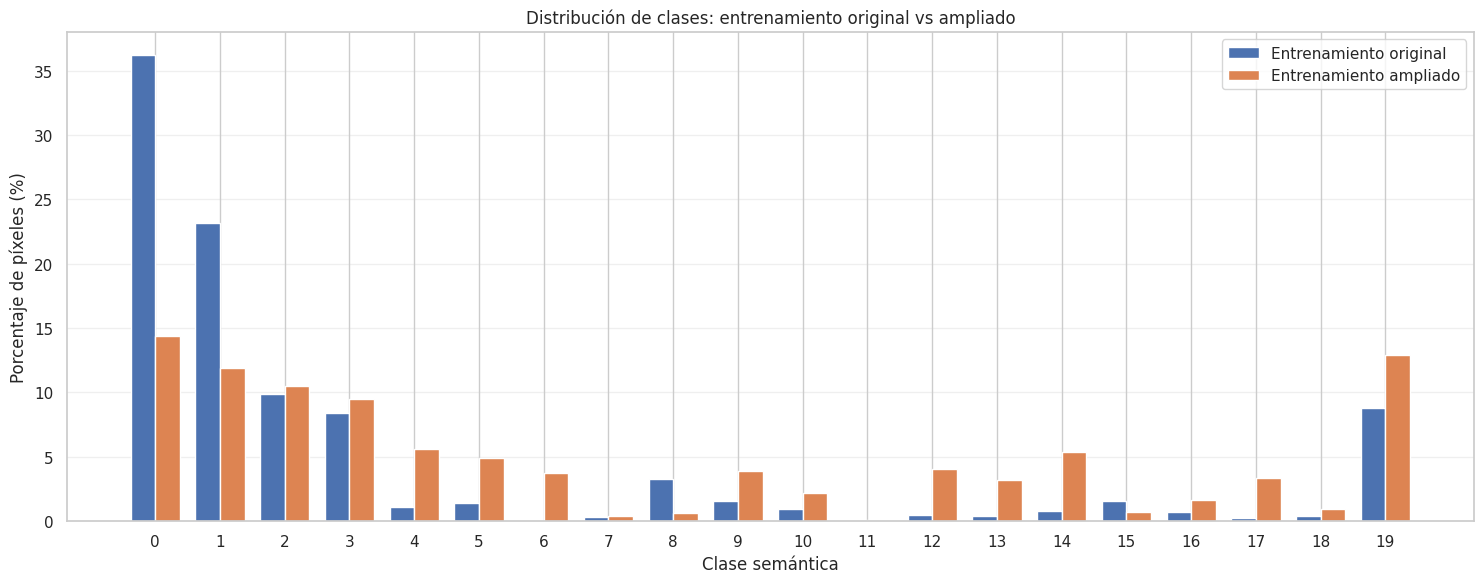


=== RESUMEN ===
Clases presentes originalmente: 19
Clases presentes en entrenamiento ampliado: 20
Píxeles clase 6 (original): 0
Píxeles clase 6 (ampliado): 7423


In [40]:

# ============================================================
# 4.17 ANÁLISIS DE DISTRIBUCIÓN DEL ENTRENAMIENTO AMPLIADO
# ============================================================


# Contar píxeles por clase
conteo_original = np.bincount(y_train.astype(int), minlength=20)
conteo_nuevo = np.bincount(y_train_ampliado.astype(int), minlength=20)

# Crear tabla comparativa
distribucion_ampliada = pd.DataFrame({
    "Clase": range(20),
    "Original": conteo_original,
    "Ampliado": conteo_nuevo
})

# Calcular porcentajes
distribucion_ampliada["% Original"] = (
    distribucion_ampliada["Original"] /
    len(y_train) * 100
)

distribucion_ampliada["% Ampliado"] = (
    distribucion_ampliada["Ampliado"] /
    len(y_train_ampliado) * 100
)

distribucion_ampliada["Cambio porcentual (pp)"] = (
    distribucion_ampliada["% Ampliado"] -
    distribucion_ampliada["% Original"]
)

print("=== DISTRIBUCIÓN DE CLASES ===")
display(distribucion_ampliada.round(2))

# Visualización
fig, ax = plt.subplots(figsize=(15, 6))

x = np.arange(20)
ancho = 0.38

ax.bar(
    x - ancho/2,
    distribucion_ampliada["% Original"],
    ancho,
    label="Entrenamiento original"
)

ax.bar(
    x + ancho/2,
    distribucion_ampliada["% Ampliado"],
    ancho,
    label="Entrenamiento ampliado"
)

ax.set_title(
    "Distribución de clases: entrenamiento original vs ampliado"
)
ax.set_xlabel("Clase semántica")
ax.set_ylabel("Porcentaje de píxeles (%)")
ax.set_xticks(x)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Resumen
print("\n=== RESUMEN ===")

print(
    "Clases presentes originalmente:",
    np.sum(conteo_original > 0)
)

print(
    "Clases presentes en entrenamiento ampliado:",
    np.sum(conteo_nuevo > 0)
)

print(
    "Píxeles clase 6 (original):",
    conteo_original[6]
)

print(
    "Píxeles clase 6 (ampliado):",
    conteo_nuevo[6]
)

In [41]:

# ============================================================
# 4.18 ENTRENAMIENTO RANDOM FOREST AMPLIADO
# ============================================================

# Configurar modelo
modelo_rf_ampliado = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("=== ENTRENAMIENTO RANDOM FOREST AMPLIADO ===")

inicio = time.time()

modelo_rf_ampliado.fit(
    X_train_ampliado,
    y_train_ampliado
)

tiempo = time.time() - inicio

print("Entrenamiento completado.")
print(f"Tiempo de entrenamiento: {tiempo:.2f} segundos")

# Predicciones
pred_train_ampliado = modelo_rf_ampliado.predict(X_train_ampliado)
pred_val_ampliado = modelo_rf_ampliado.predict(X_val)

# Evaluación
def evaluar_rf(y_real, y_pred):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Macro F1": f1_score(
            y_real, y_pred,
            labels=list(range(20)),
            average="macro",
            zero_division=0
        ),
        "Macro IoU": jaccard_score(
            y_real, y_pred,
            labels=list(range(20)),
            average="macro",
            zero_division=0
        )
    }

metricas_train = evaluar_rf(
    y_train_ampliado,
    pred_train_ampliado
)

metricas_val = evaluar_rf(
    y_val,
    pred_val_ampliado
)

resultados_ampliado = pd.DataFrame({
    "Entrenamiento": metricas_train,
    "Validación": metricas_val
})

resultados_ampliado["Diferencia"] = (
    resultados_ampliado["Entrenamiento"] -
    resultados_ampliado["Validación"]
)

print("\n=== RESULTADOS RANDOM FOREST AMPLIADO ===")
display(resultados_ampliado.round(4))

# Comparación con modelos anteriores
comparacion_cuatro_modelos = comparacion_tres_modelos.copy()

comparacion_cuatro_modelos["Ampliado"] = [
    metricas_val["Accuracy"],
    metricas_val["Macro F1"],
    metricas_val["Macro IoU"]
]

print("\n=== COMPARACIÓN DE LOS CUATRO MODELOS ===")
display(comparacion_cuatro_modelos.round(4))


=== ENTRENAMIENTO RANDOM FOREST AMPLIADO ===
Entrenamiento completado.
Tiempo de entrenamiento: 248.95 segundos

=== RESULTADOS RANDOM FOREST AMPLIADO ===


,Entrenamiento,Validación,Diferencia
Accuracy,0.6971,0.3898,0.3073
Macro F1,0.7545,0.1425,0.6121
Macro IoU,0.6220,0.0974,0.5247



=== COMPARACIÓN DE LOS CUATRO MODELOS ===


,Baseline,Regularizado,Balanceado,Ampliado
Accuracy,0.5142,0.5326,0.4520,0.3898
Macro F1,0.1465,0.1476,0.1628,0.1425
Macro IoU,0.1021,0.1046,0.1084,0.0974



## 5. Selección y justificación de métricas de evaluación

Para evaluar el desempeño del modelo Random Forest se seleccionaron tres métricas principales: Accuracy, Macro F1-Score y Macro Intersection over Union (IoU).

**Accuracy:** permite conocer la proporción total de píxeles clasificados correctamente. Sin embargo, debido al desbalance entre las clases del dataset PASTIS24, esta métrica puede favorecer a las categorías mayoritarias.

**Macro F1-Score:** combina precisión y exhaustividad (recall) mediante su media armónica. Al calcular el promedio por clase, permite evaluar el desempeño del modelo sin dar mayor peso a las categorías más frecuentes.

**Macro IoU:** mide la superposición entre las clases reales y las predichas. Es especialmente relevante para tareas de segmentación semántica, ya que permite evaluar la coincidencia de las regiones clasificadas.

Debido a la naturaleza multiclase del problema y al desbalance observado, Macro F1 y Macro IoU se consideran las métricas principales para comparar los modelos.

La matriz de confusión complementa este análisis, permitiendo identificar las clases que presentan mayores errores de clasificación.


=== RESUMEN GENERAL DE MÉTRICAS ===


,Baseline,Regularizado,Balanceado,Ampliado
Accuracy,0.5142,0.5326,0.4520,0.3898
Macro F1,0.1465,0.1476,0.1628,0.1425
Macro IoU,0.1021,0.1046,0.1084,0.0974



=== MEJOR MODELO POR MÉTRICA ===
Accuracy: Regularizado (0.5326)
Macro F1: Balanceado (0.1628)
Macro IoU: Balanceado (0.1084)


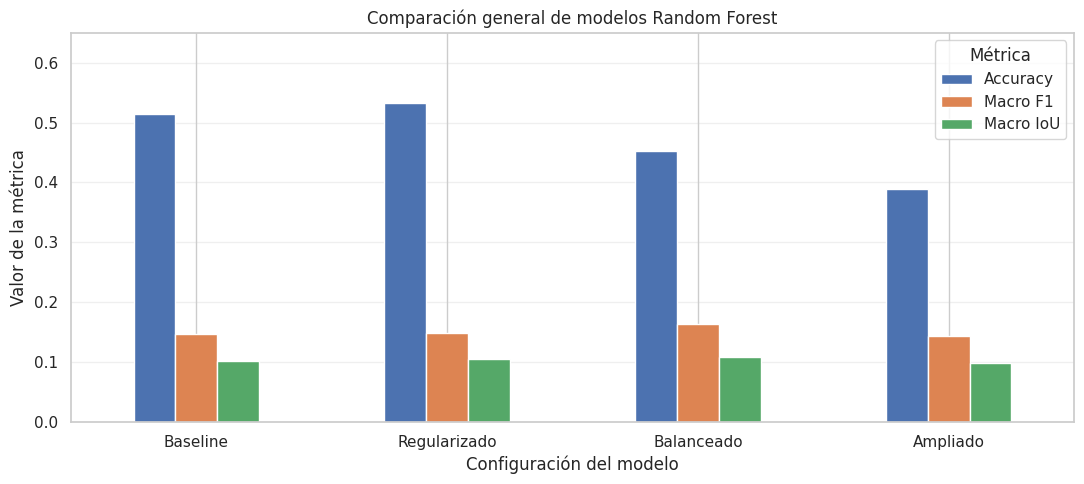

In [42]:
# ============================================================
# 5. CONSOLIDACIÓN DE MÉTRICAS DEL BASELINE
# ============================================================

# Recuperar resultados de los modelos entrenados
resumen_metricas = comparacion_cuatro_modelos.copy()

print("=== RESUMEN GENERAL DE MÉTRICAS ===")
display(resumen_metricas.round(4))

# Identificar el mejor modelo por métrica
print("\n=== MEJOR MODELO POR MÉTRICA ===")

for metrica in resumen_metricas.index:
    mejor_modelo = resumen_metricas.loc[metrica].idxmax()
    mejor_valor = resumen_metricas.loc[metrica].max()

    print(
        f"{metrica}: {mejor_modelo} "
        f"({mejor_valor:.4f})"
    )

# Visualización comparativa
ax = resumen_metricas.T.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

plt.title("Comparación general de modelos Random Forest")
plt.xlabel("Configuración del modelo")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 0.65)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()



## 6. Evaluación del Desempeño Mínimo Aceptable

Para determinar si el modelo baseline presenta un rendimiento adecuado, se establecen criterios mínimos de desempeño considerando la naturaleza multiclase del problema de segmentación semántica.

Se proponen los siguientes umbrales exploratorios:

- **Accuracy ≥ 0.60:** al menos el 60% de los píxeles deben clasificarse correctamente.
- **Macro F1 ≥ 0.30:** se espera un desempeño mínimo entre las diferentes clases, considerando el desbalance del conjunto de datos.
- **Macro IoU ≥ 0.20:** se busca un nivel mínimo de coincidencia entre las clases reales y las predicciones.

Estos valores se utilizan como referencias internas para evaluar el baseline y orientar el desarrollo de modelos posteriores. No representan umbrales establecidos por la literatura ni requisitos externos del proyecto.

El modelo seleccionado para esta evaluación es Random Forest balanceado, debido a que obtuvo los mejores resultados de Macro F1 y Macro IoU durante la validación.


=== EVALUACIÓN DEL DESEMPEÑO MÍNIMO ===


,Métrica,Resultado,Mínimo esperado,Cumple,Estado
0,Accuracy,0.4520,0.6,False,No cumple
1,Macro F1,0.1628,0.3,False,No cumple
2,Macro IoU,0.1084,0.2,False,No cumple



=== RESUMEN ===
Criterios cumplidos: 0 de 3
El baseline no alcanza el desempeño mínimo propuesto.


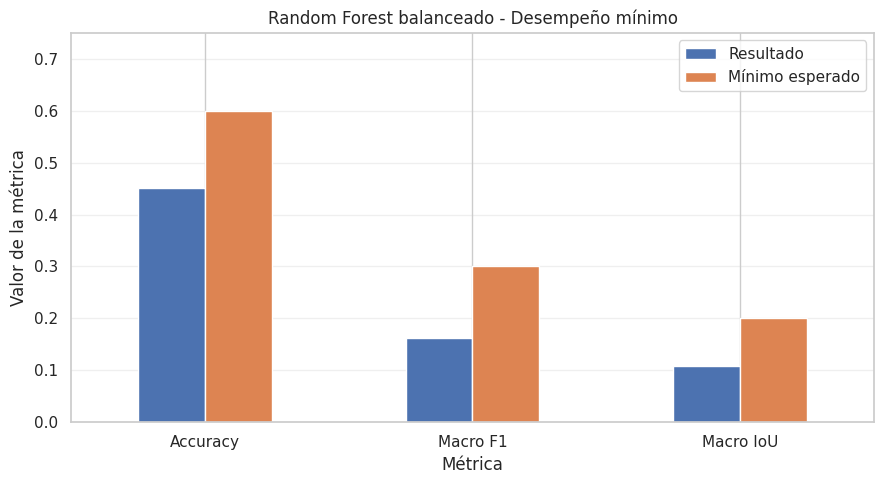

In [43]:
# ============================================================
# 6 EVALUACIÓN DEL DESEMPEÑO MÍNIMO ACEPTABLE
# ============================================================

# Umbrales exploratorios propuestos
umbrales = {
    "Accuracy": 0.60,
    "Macro F1": 0.30,
    "Macro IoU": 0.20
}

# Resultados del modelo seleccionado
metricas_baseline = comparacion_cuatro_modelos["Balanceado"]

# Construir tabla de evaluación
evaluacion_minima = pd.DataFrame({
    "Métrica": list(umbrales.keys()),
    "Resultado": [
        metricas_baseline[m] for m in umbrales
    ],
    "Mínimo esperado": list(umbrales.values())
})

evaluacion_minima["Cumple"] = (
    evaluacion_minima["Resultado"] >=
    evaluacion_minima["Mínimo esperado"]
)

evaluacion_minima["Estado"] = evaluacion_minima[
    "Cumple"
].map({
    True: "Cumple",
    False: "No cumple"
})

print("=== EVALUACIÓN DEL DESEMPEÑO MÍNIMO ===")
display(evaluacion_minima.round(4))

# Resumen
criterios_cumplidos = evaluacion_minima["Cumple"].sum()

print("\n=== RESUMEN ===")
print(
    f"Criterios cumplidos: "
    f"{criterios_cumplidos} de {len(umbrales)}"
)

if criterios_cumplidos == len(umbrales):
    print("El baseline cumple los criterios propuestos.")
else:
    print("El baseline no alcanza el desempeño mínimo propuesto.")

# Visualización
ax = evaluacion_minima.set_index("Métrica")[
    ["Resultado", "Mínimo esperado"]
].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Random Forest balanceado - Desempeño mínimo")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 0.75)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Conclusiones Metodológicas CRISP-ML(Q)

### Resultados principales

Durante esta etapa del proyecto se implementó un modelo Random Forest como algoritmo baseline para la clasificación de píxeles de imágenes satelitales del dataset PASTIS.

Se utilizaron 52 características derivadas de bandas espectrales e índices de vegetación, considerando estadísticas temporales como media, desviación estándar, mínimo y máximo.

Se evaluaron cuatro configuraciones del algoritmo: baseline original, regularizado, balanceado y entrenamiento ampliado.

El modelo regularizado obtuvo la mayor Accuracy en validación (0.5326), mientras que el modelo balanceado presentó los mejores resultados de Macro F1 (0.1628) y Macro IoU (0.1084).

Debido a la naturaleza multiclase del problema, se seleccionó el modelo balanceado como referencia para las siguientes etapas.

### Limitaciones identificadas

Los experimentos permitieron identificar las siguientes limitaciones:

- **Sobreajuste:** se observaron diferencias considerables entre los resultados de entrenamiento y validación.
- **Desbalance de clases:** algunas categorías presentaron una representación significativamente menor que otras.
- **Generalización limitada:** los modelos no alcanzaron los umbrales mínimos exploratorios establecidos.
- **Representación temporal:** el enfoque basado en estadísticas resumidas no conserva completamente la evolución temporal de los cultivos.

Aunque la ampliación del entrenamiento permitió incorporar las 20 clases semánticas y aumentar la cantidad de observaciones, no produjo mejoras en las métricas de validación.

### Oportunidades de mejora

Los resultados obtenidos permiten establecer las siguientes líneas de trabajo:

1. Explorar arquitecturas especializadas en series temporales de imágenes satelitales, como Vision Transformers.
2. Evaluar estrategias adicionales para manejar el desbalance entre clases.
3. Incorporar información temporal de manera más completa durante el entrenamiento.
4. Realizar evaluaciones por clase para identificar categorías con mayores dificultades de clasificación.
5. Comparar los resultados de modelos posteriores utilizando las mismas particiones y métricas de evaluación.

### Conclusión general

La implementación del Random Forest permitió establecer un punto de referencia cuantitativo para el problema de segmentación semántica de cultivos.

Si bien los resultados no alcanzaron el desempeño mínimo esperado, los experimentos permitieron identificar problemas relacionados con el desbalance de clases, el sobreajuste y la capacidad de generalización.

Estos hallazgos servirán como base para evaluar modelos más avanzados durante las siguientes etapas del Proyecto Integrador, particularmente aquellos diseñados para procesar series temporales de imágenes satelitales.